# In this Notebook, we analyse the results of manual segmentation of lumens

---

# Loading utility

In [1]:
%matplotlib inline
"""
Utility cell
"""


# Imports

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os
import subprocess
import re
from scipy import stats
from statannot import add_stat_annotation

sns.set()
#sns.axes_style('ticks')
# Utility functions

def list_csv_files(csv_folder_path):
    csv_files_list = []
    for root, directory, filenames in os.walk(csv_folder_path):
        for filename in filenames:
#            print(os.path.join(root, filename))
            csv_files_list.append(os.path.join(root, filename))
    return csv_files_list

def get_dataset_from_csv_folder(csv_folder_path):
    
    # Load the data
    csv_files_list = list_csv_files(csv_folder_path)
    data_frames_list = []
    for file in csv_files_list:
        # Iterate through the dataset of every file to catch only the "Entire organoids" for instance
        csv_df = pd.read_csv(file, sep=',', engine="python")
        csv_df['File_label'] = os.path.basename(file)
        data_frames_list.append(csv_df)
        # Add a label to the dataframe with the file name
    # Concatenate all the data frames in the filtered list
    df = pd.concat(data_frames_list)
   
    return df

def parse_full_id_swe_nuc_lumen(roi_list):
    """
    Updated: 18/08/2023
    From a list of ROI
    Parse the name of the roi of the form : swe_2_t160, nuc_N4_t180
    L_id_tT or L_Nid_tT
    Where 
    L : lumen type (e.g. swe or nuc)
    id : id of the location measured for a swe lumen; prepended by a "N" for nuc lumen
    T : frame where the measurement was taken
    Label the location type : swe or nuc
    Get the timestamp
    
    Returns : location_full_id_list, numerical_id_list, location_type_list, timestamp_list
    """
    
    location_type_list = []
    location_full_id_list = []
    numerical_id_list = []
    timestamp_list = []
    
    for index, label in enumerate(roi_list):
        # Perform successive regex search to label 
        location_search = re.search('swe_\d+', label)
        if location_search is not None:
            # Store the full_id
            location_full_id_list.append(location_search.group())
            # The result of the regex is not empty, we know that the type is a "Tip"
            location_type_list.append('Swe')
            # We also extract the numerical id 
            numerical_id_search = re.search('\d+', location_search.group())
            numerical_id = int(numerical_id_search.group())
            numerical_id_list.append(numerical_id)
        else:
            location_search = re.search('nuc_\d+', label)
            if location_search is not None:
                location_full_id_list.append(location_search.group())
                location_type_list.append('Nuc')
                numerical_id_search = re.search('\d+', location_search.group())
                numerical_id = int(numerical_id_search.group())
                numerical_id_list.append(numerical_id)
            else:
                location_full_id_list.append('Undefined')
                location_type_list.append('Undefined')
                numerical_id_list.append(np.nan)

        # Look for the timestamp
#        print("label searches : ", label)
        timestamp_search = re.search('_t(\d+)', label)
        timestamp_id = int(timestamp_search.group(1))
        timestamp_list.append(timestamp_id)
        
       
    return location_full_id_list, numerical_id_list, location_type_list, timestamp_list



def prepare_nuc_swe_lumen_dataframe(csv_folder, experiment_name, timestep):
    """
    Updated: 18/08/2023
    Performs parsing of a folder containing csv files describing the nucleating or swelling lumen of live data organoids
    Sort the results of the parsing into a DataFrame

    Parameters
    ------
    csv_folder : str, path to the csv folder containing the csv files
    experiment_name : str, name of the experiment
    timestep : int or float, value in minutes between two frames
    
    Returns : 
    
    live_csv_df : pandas dataframe, contains the entire processed data from the csv files
    
    """
    live_csv_df = get_dataset_from_csv_folder(csv_folder)
#    print(live_csv_df.head)
    roi_list = list(live_csv_df['Label'])                    


    
    location_full_id_list, numerical_id_list, location_type_list, timestamp_list = parse_full_id_swe_nuc_lumen(roi_list)                

    print("Timestamp list is: ", timestamp_list)

    live_csv_df['Location_full_id'] = location_full_id_list               
    live_csv_df['Numerical_id'] = numerical_id_list               
    live_csv_df['Location_type'] = location_type_list               
    live_csv_df['Timestamp_frame'] = timestamp_list
    # Define the time step to convert T (in frames) to "minutes after the beginning of the experiment"
    live_csv_df['Timestamp_minutes'] = live_csv_df['Timestamp_frame'] * timestep



#    print(live_csv_df.head)
#    print('Length : ', len(live_csv_df))

    # For further comparisons between datasets, save the loaded df
    live_csv_df['Experiment_name'] = experiment_name
    
    # Since an experiment might contain several imaging positions with lumens labelled the same way, create a unique identifier
    live_csv_df['Unique_ID'] = live_csv_df['Experiment_name'] + "_" + live_csv_df['File_label'] + "_" + live_csv_df['Location_full_id']
    

    # To simplify everything afterwards, make sure that we sort things here
    live_csv_df.sort_values(by=["Unique_ID", "Timestamp_frame"]) 
    
    
    return live_csv_df


def normalize_timestamp_minutes(df_to_analyze, timestep):
    """
    Updated: 18/08/2023
    Takes a dataframe including a "Timestamp_minutes" with objects possessing different Unique_ID
    and creates a new "Normalized timestamps minutes" column where every track begins at 0.
    
    Parameters:
    ------
    df_to_analyze : pandas dataframe with a "Timestamp_minutes" and a "Unique_ID" column
    timestep : int or float, value in minutes between two frames
    
    Returns:
    ------
    df_to_analyze : input pandas dataframe with a newly appended "Normalized timestamp minutes" column where every track starts at 0
    """    

    groups_full_id_grouped = dict(list(df_to_analyze.groupby(['Unique_ID'])))
    # Renormalize so every track begins at zero
    normalized_timestamp_minutes = []
    for key in groups_full_id_grouped.keys():
        # Get the first element
        df = groups_full_id_grouped[key]
#        print("Before normalizing")
#        print(np.sort(np.array(df['Timestamp_minutes'])))
        start_time = np.array(df['Timestamp_minutes']).min()
    
    
        # Sort before normalizing
        df.sort_values(['Timestamp_minutes'],inplace = True)
        
        df['Normalized timestamp minutes'] = np.cumsum(np.diff(df['Timestamp_minutes'].copy(), prepend=start_time))
#        print("start_time :", start_time)
#        print("time_step : ", timestep)
#        print("Before normalizing :", np.sort(df['Timestamp_minutes']))

#        print("After normalizing")
#        print(np.sort(np.array(df['Normalized timestamp minutes'])))
    #    print(df)

    #    normalized_timestamp_minutes.append(df['Normalized timestamp minutes'])
        normalized_timestamp_minutes.append(df)
        
    ## Merge together the different array packed into one list
    normalized_timestamp_minutes_df = pd.concat(normalized_timestamp_minutes)
#    print("Colonnes normalized df : ",normalized_timestamp_minutes_df.columns)
#    print("Colonnes df to analyze : ",df_to_analyze.columns)

#    df_to_analyze = pd.merge(df_to_analyze, normalized_timestamp_minutes_df[['Normalized timestamp minutes', 'Numerical_id','Timestamp_minutes']],
#                                    on=['Numerical_id','Timestamp_minutes'])
    df_to_analyze = pd.merge(df_to_analyze, normalized_timestamp_minutes_df[['Normalized timestamp minutes', 'Unique_ID','Timestamp_minutes']],
                                    on=['Unique_ID','Timestamp_minutes'])
    #new_branches_only_df['Normalized timestamp minutes'] = normalized_timestamp_minutes_df
    print("normalized_timestamp_minutes_df")
#    print(df_to_analyze)
    return df_to_analyze



def filter_out_points_by_len(df_to_analyze, filter_condition='Numerical_id', threshold=1):
    """
    Groups a df with a filter_condition and returns only the parts where the number of elements is > threshold
    
    Parameters:
    ------
    df_to_analyze : Pandas DataFrame
    filter_condition : str
    threshold : int
    
    Returns:
    ------
    element_len_above_threshold_df : Pandas DataFrame
    """
    groups_full_id_grouped = dict(list(df_to_analyze.groupby([filter_condition])))
    element_len_above_threshold_df_list = []
    for key in groups_full_id_grouped.keys():
        # Get the first element
        df = groups_full_id_grouped[key]
        if len(df) > threshold: 
            element_len_above_threshold_df_list.append(df)
        
    ## Merge together the different array packed into one list
    element_len_above_threshold_df = pd.concat(element_len_above_threshold_df_list)
    
#    print(bigger_than_one_df)
    return element_len_above_threshold_df



def compute_linear_slope(df_to_analyze, x_reg_parameter, y_reg_parameter, plot_on=False, plot_vector_range=10, plot_vector_step=1, color="tab:green"):
    """
    Updated: 19/08/2023
    Performs a linear regression on a dataframe, grouping by Unique_ID
    
    Parameters:
    -----
    df : pandas DataFrame
    x_reg_parameter : str, column name of the df DataFrame to serve as the x parameter for the linear regression 
    y_reg_parameter : str, column name of the df DataFrame to serve as the y parameter for the linear regression 
    plot_on : bool, enables or disable the plotting function
    plot_vector_range : float, range of the x vector when plotting
    plot_vector_step : float, step of the x vector when plotting
    
    Returns:
    -----
    slope_df : pandas DataFrame, contains the slope and the intercept of each track
    """
    with sns.axes_style('ticks'):
        if plot_on is True:
            fig, ax = plt.subplots()

        experiment_name_grouped = df_to_analyze.groupby(['Unique_ID'])
        groups_experiment_name_grouped = dict(list(experiment_name_grouped))
        slope_list = []
        location_type_list = []
        intercept_list = []
        for key in groups_experiment_name_grouped.keys():
            df = groups_experiment_name_grouped[key]

#            df_grouped_by_track = df.groupby('Numerical_id')    
#            # Get the individual track to compute their slopes
#            df_split_by_track_list = [df_grouped_by_track.get_group(x) for x in df_grouped_by_track.groups]
            # We need at least 2 elements to perform a linear regression
            if len(df)>1: 

                slope, intercept, r_value, p_value, std_err = stats.linregress(df[x_reg_parameter], df[y_reg_parameter])
                ypred = intercept + slope * df[x_reg_parameter]
            else:
                print("Warning less than 2 points to perform the regression, returning NaN for ", df["Unique_ID"].unique())
                slope = np.nan
                intercept = np.nan
                r_value = np.nan 
                p_value = np.nan
                std_err = np.nan
                
            first_elem = df.iloc[0]
            location_type = first_elem['Location_type']
            # Save the slope and the experiment type for future use to plot the mean 
            slope_list.append(slope)
            intercept_list.append(intercept)
            location_type_list.append(location_type)
    #        print(experiment_type)
            if plot_on is True :
                plt.plot(df[x_reg_parameter], ypred, 
                         linestyle='--',
                         alpha=0.125, label=location_type,color=color)

        slope_df = {'Location_type':location_type_list, 'Slope':slope_list, 'Intercept':intercept_list}
        slope_df = pd.DataFrame(data=slope_df)
        return slope_df
   
    
def savefigure(figure_path, figure_name):
    """
    Save the figure in png and svg formats
    
    Parameters:
    ------
    figure_path : str, path to the desired save folder
    figure_name : str, name of the figure
    """
     
    path_to_inkscape = "C:\\Program Files\\Inkscape\\bin\\inkscape.exe"
    
    plt.savefig(figure_path + figure_name + '.svg', bbox_inches='tight')
    plt.savefig(figure_path + figure_name + '.png', bbox_inches='tight')   
    
    # Calls Inkscape as a subprocess to create an emf version of the figure, based on the previously created .svg
    svgFile = os.path.join(figure_path, figure_name+".svg")
    emfFile = os.path.join(figure_path, figure_name+".emf")
    subprocess.call([path_to_inkscape, svgFile, "--export-filename", emfFile], shell=True)   
    
    
    
def prepare_normalized_shape_column(original_df, shape_columns_list, name_time_frame_column, provided_reference_frame=None):
    """
    Updated: 18/08/2023
    """
    #df_grouped = original_df.groupby(["File_label"])
    df_grouped = original_df.groupby(["Unique_ID"])
    groups_df_grouped = dict(list(df_grouped))
    df_list = []
    for key in groups_df_grouped.keys():
        
        # Treat one df at a time
        print(key)
        df = groups_df_grouped[key]
        
        # If no specific reference frame is provided, pick the first available one
        if provided_reference_frame is None:
            # Do a sorting by time to really be sure to pick the first available frame 
            df.sort_values(by=[name_time_frame_column])
            #print(df.head())
            print(df[name_time_frame_column])
            reference_frame = df[name_time_frame_column].iloc[0]
            print("Selecting the first available time frame ({}) for normalization.".format(reference_frame))
        
        else:
            reference_frame = provided_reference_frame
        
        
        for shape in shape_columns_list:
            print(shape)
            # Don't forget to add the .values[0] to select the actual value and not the full index 
            # Possibly the frame_drug_added is missing

                
            try:
                ref_value = df[shape].loc[df[name_time_frame_column] == reference_frame]
                ref_value = ref_value.values[0]
                print("ref_value is : ", ref_value, "at reference frame ", reference_frame )
            except IndexError:
                print("The corresponding value for the selected reference frame (Frame {0}) is missing ".format(reference_frame))
                
            try:
                df["Normalized " + shape] = df[shape] / ref_value
            except ZeroDivisionError:
                print("Ref value is zero")

        df_list.append(df)
        print("-"*20)
    
    return pd.concat(df_list)


def hacky_count_unique_id_nuc_swe(df):
    """
    Really hacky way of counting the number of samples by parsing the Unique_ID column of the input dataframe
    """

    nuc_counter = 0
    swe_counter = 0
    for i in df["Unique_id"].unique():
        if("_nuc_" in i):
            print("found a nuc")
            nuc_counter+=1
        elif ("_swe_" in i):
            print("found a swe")
            swe_counter+=1

    print("Total nuc : ", nuc_counter)
    print("Total swe : ", swe_counter)
    
def raise_allowed_flags_if_fusion(df, disable_all=False):
    """
    This function creates flags to disable the datapoints in a tracks that contain a fusion event.
    This is useful for instance to compute growth rates only prior a fusion event.
    For safety, this function performs a sorting by Unique_ID and by time 
    
    Parameters:
    -------
    df : pandas DataFrame to process
    disable_all : bool ; if True, this will raise a disabling flag for the entire track. Otherwise, only the points AT and AFTER the fusion event will be disabled.
    
    Returns:
    -------
    flagged_df : pandas DataFrame ; contains the same data as the original df, sorted, and with a column of flags
    """
    
    
    print("For safety, this function ({}) performs a sorting by Unique ID and by time, this will reset the index".format(raise_allowed_flags_if_fusion.__name__))
    flagged_df = df.copy()
    print(flagged_df["Label"].loc[142])
    flagged_df.sort_values(by=["Unique_ID", "Timestamp_frame"]).reset_index(drop=True, inplace=True) # Reset the index to avoid any weird stuff
#    allow_flags = [True for i in range(len(flagged_df))] # By default everything is allowed
    flagged_df["Allowed flags if no/before fusion"] = True
    for uid in flagged_df["Unique_ID"].unique():
        print("Treating ", uid)
        print("Correspond to actual indices: ", flagged_df.loc[flagged_df["Unique_ID"]== uid].index)
        # Check if there was any fusion reported in the current Unique_ID track being parsed
        if any(flagged_df["Fusion event"].loc[flagged_df["Unique_ID"]==uid]):
            print("Tap: ",flagged_df.loc[(flagged_df["Unique_ID"]==uid) & (flagged_df["Fusion event"] == True)].index)
            hit_index = flagged_df.loc[(flagged_df["Unique_ID"] == uid) & (flagged_df["Fusion event"] == True)].index[0] # This gives me the index at which I found a Fusion event for the current track uid parsed
            # BOOOOOOOP check that above
           # hit_index = hit_index[0]
            print("Boop hit_index : ",hit_index)
            index_list = flagged_df.loc[flagged_df["Unique_ID"] == uid].index
            print("Index_list after flagging: ", index_list)
            max_index = max(index_list)
            min_index = min(index_list)

            if disable_all == False:
                # We only disable the datapoints AT AND AFTER the fusion event
                for i in range(hit_index, max_index+1):
                    #allow_flags[i] = False
                    flagged_df["Allowed flags if no/before fusion"].loc[i] = False 
            else:
                # We disable the entire track where the fusion event was spotted
                for i in range(min_index, max_index+1):
                    #allow_flags[i] = False
                    flagged_df["Allowed flags if no/before fusion"].loc[i] = False
            
            #Sanity check
            print("*"*50)
            # BE SUPER CAREFUL WITH LOC AND ILOC
            print("At hit_index ",hit_index, "there is ", flagged_df["Label"].loc[hit_index])
            print("*"*50)
            
#    flagged_df["Allowed flags if no/before fusion"] = allow_flags
    
    
    return flagged_df



   

 

## Loading dataset

In [2]:
"""
Loading the Excel file containing the observations
"""

## Folder to save produced graphs
graphs_folder = "./Graphs/"
print(graphs_folder)
## Loading dataset
measurement_folder = "./csv/"
print(measurement_folder)

experiment_name = "230217_9591_Day12_14_part2"

timestep_230217_sec = 6553 # seconds
timestep_230217_min = timestep_230217_sec / 60.0 # minutes

df_230217 = prepare_nuc_swe_lumen_dataframe(measurement_folder, experiment_name, timestep_230217_min)
df_230217 = normalize_timestamp_minutes(df_230217, timestep_230217_min)

# Tag the lumens that have a fusion event
df_230217["Fusion event"] = ["_fus" in i for i in df_230217["Label"]] # Iterates through the labels and appends True/False depending on whether it finds "_fus" in the label name



# Normalise some parameters of interest, with respect to the first available frame for each lumen
shape_columns_list = ["Area", "Major", "Minor"]
name_time_frame_column = "Timestamp_frame"
start_frame = None # Indicates that we take the first available frame
start_frame_normalized_df_230217 = prepare_normalized_shape_column(df_230217, shape_columns_list, name_time_frame_column, start_frame)


./Graphs/
./csv/
Timestamp list is:  [1, 2, 11, 13, 15, 17, 19, 21, 23, 25, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 9, 11, 13, 15, 17, 19, 21, 23, 25, 7, 9, 11, 13, 15, 17, 19, 21, 23, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 3, 5, 7, 9, 11, 13, 15, 17, 1, 3, 5, 7, 9, 11, 13, 15, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 13, 15, 17, 19, 21, 23, 25, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 4, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 5, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 9, 11, 13, 15, 17, 19, 21, 23, 7, 17, 19, 21, 23, 24, 20, 21, 22, 23, 24, 2, 3, 5, 7, 9, 11, 12, 14, 13, 15, 9, 11, 13, 15, 17, 19, 23, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
normalized_timestamp_minutes_df
230217_9591_Day12_14_part2_RoiSe

## Plotting section

No handles with labels found to put in legend.


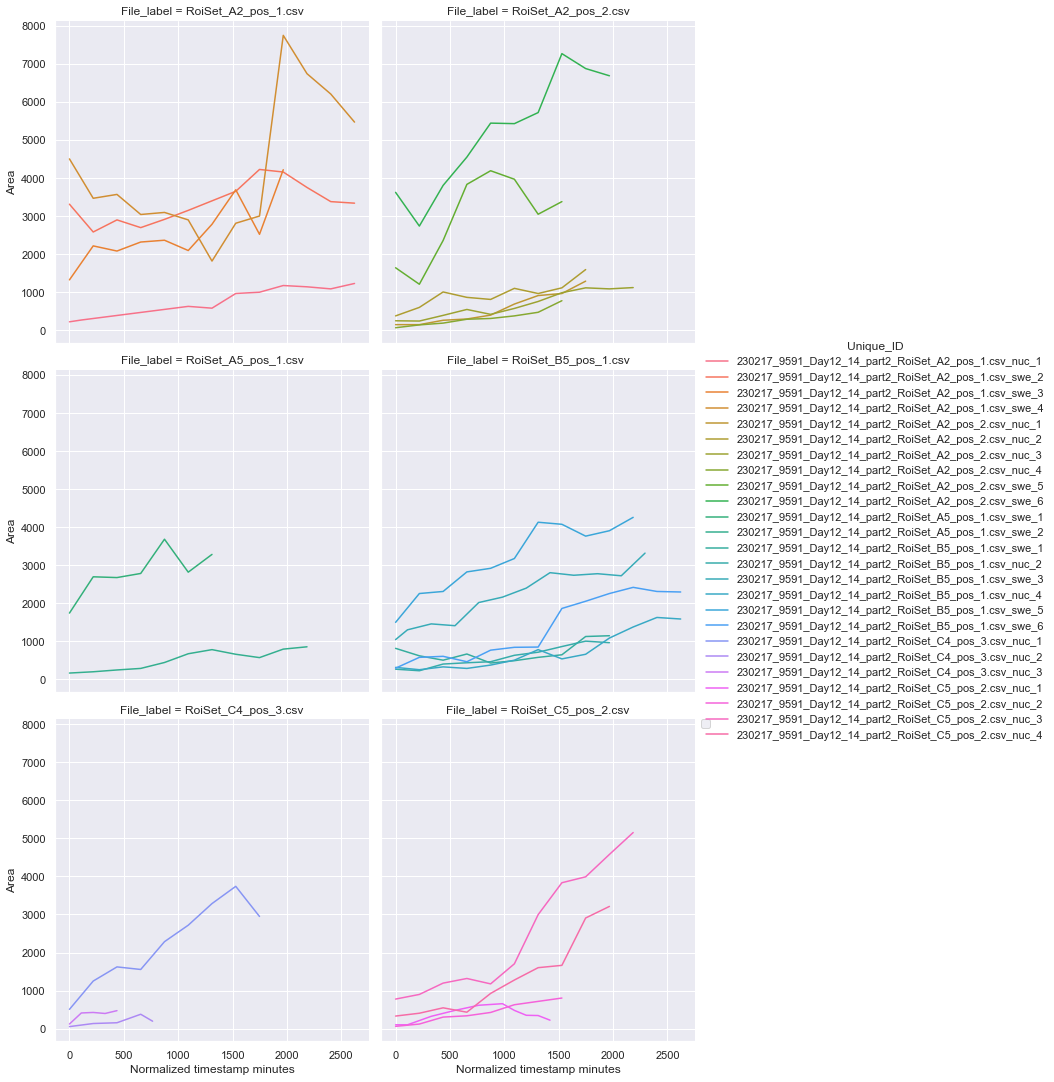

In [3]:
sns.relplot(x="Normalized timestamp minutes", y="Area", hue="Unique_ID", 
            kind="line",
            col="File_label",
            col_wrap=2,
            data=df_230217)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

No handles with labels found to put in legend.


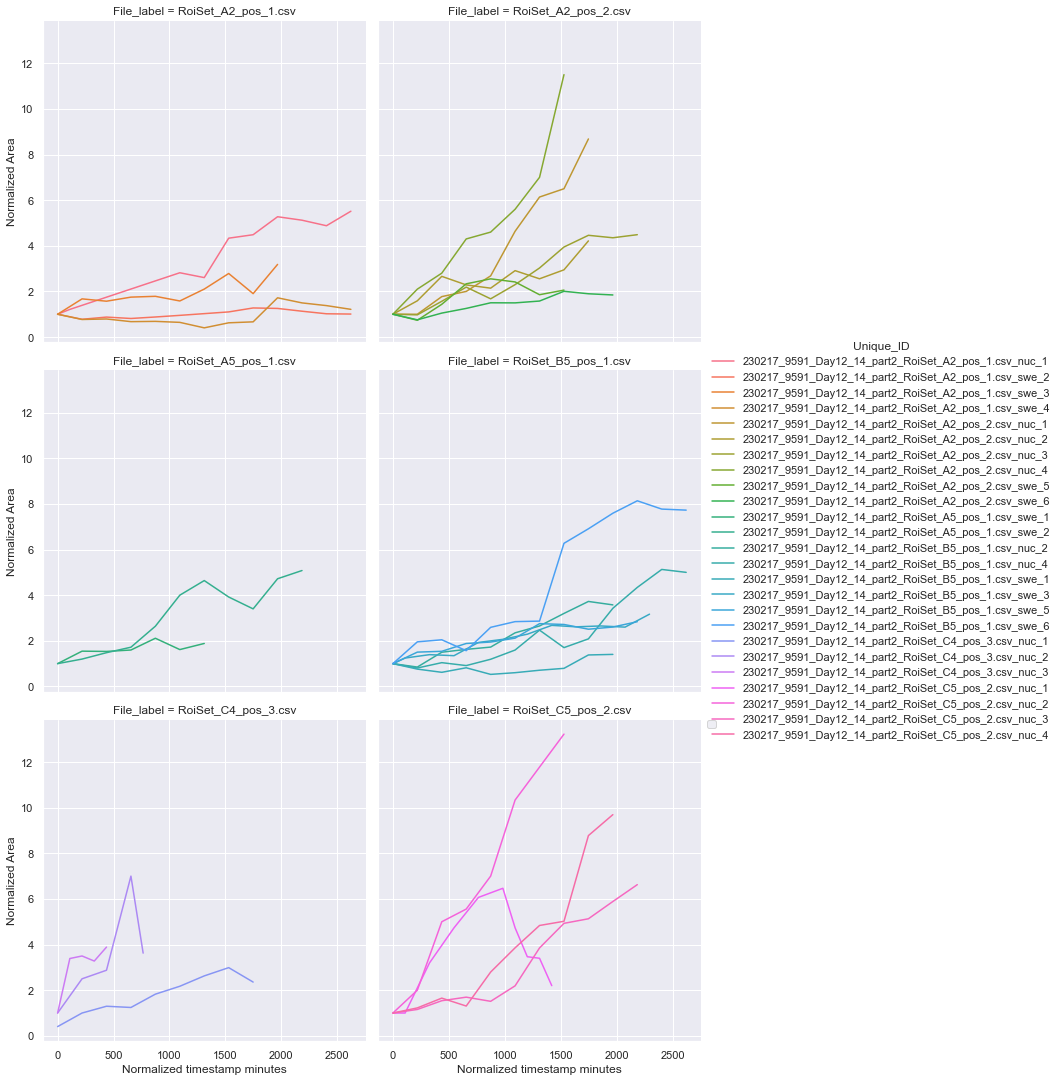

In [4]:
# Plotting the Normalised Area grouping graphs by position in the 
sns.relplot(x="Normalized timestamp minutes", y="Normalized Area", hue="Unique_ID", 
            kind="line",
            col="File_label",
            col_wrap=2,
            data=start_frame_normalized_df_230217)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

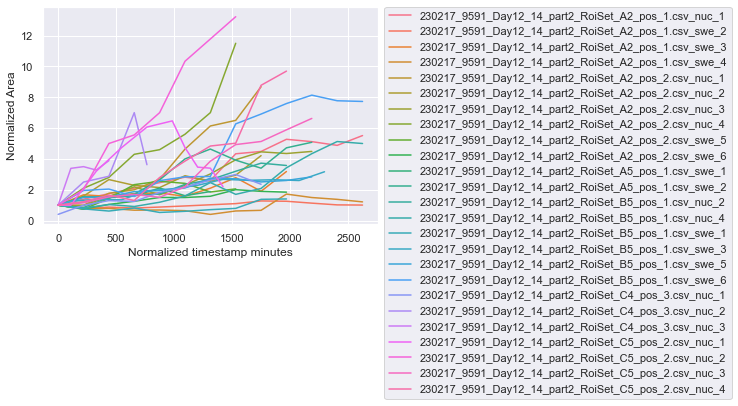

In [5]:
sns.lineplot(x="Normalized timestamp minutes", y="Normalized Area", hue="Unique_ID", 
            data=start_frame_normalized_df_230217)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

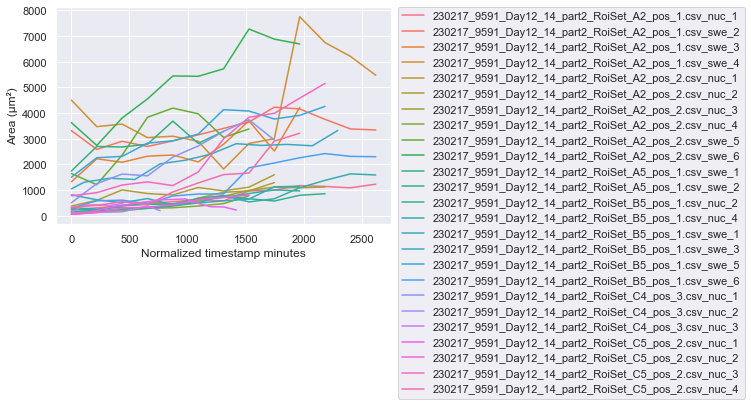

In [6]:
sns.lineplot(x="Normalized timestamp minutes", y="Area", hue="Unique_ID", 
            data=start_frame_normalized_df_230217)
plt.ylabel("Area (µm²)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

No handles with labels found to put in legend.


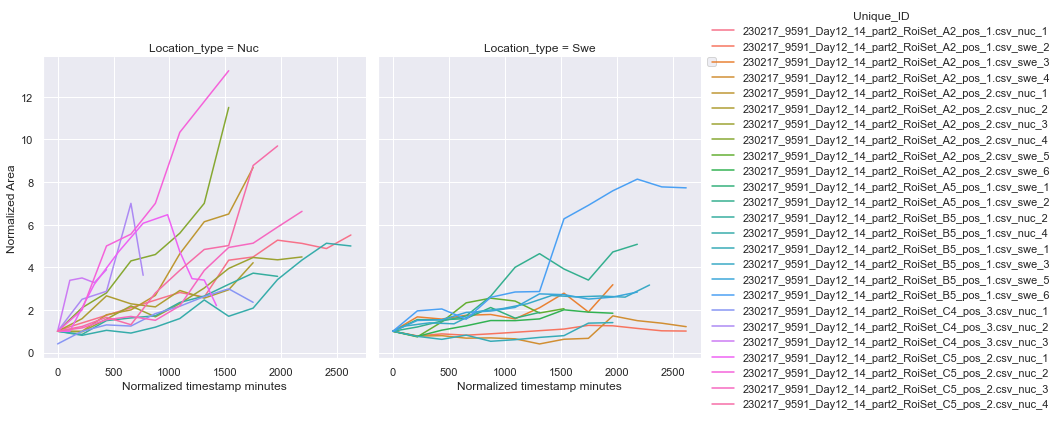

In [7]:
sns.relplot(x="Normalized timestamp minutes", y="Normalized Area", hue="Unique_ID", 
            kind="line",
            col="Location_type",
            col_wrap=2,
            data=start_frame_normalized_df_230217)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

No handles with labels found to put in legend.


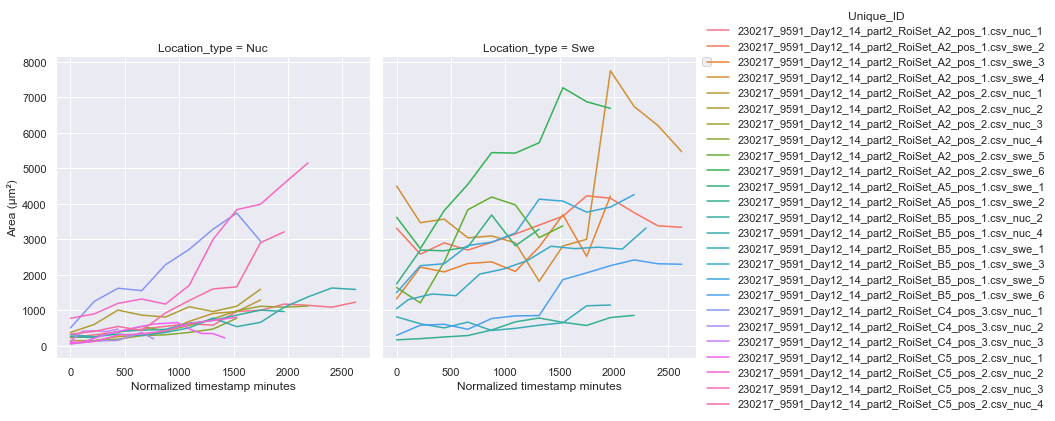

In [8]:
g = sns.relplot(x="Normalized timestamp minutes", y="Area", hue="Unique_ID", 
            kind="line",
            col="Location_type",
            col_wrap=2,
            data=start_frame_normalized_df_230217)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
for ax in g.axes.flat:
    ax.set_ylabel("Area (µm²)")

# Need to decide whether we want Nuc and Swe plotted together

# The lumen swelling rates are probably depending on a multitude of factors


## If we are to compute the swelling rates, we may want to look at the median to avoid the outliers due to fusion, OR exclude explicitely the fusion events from the analysis.

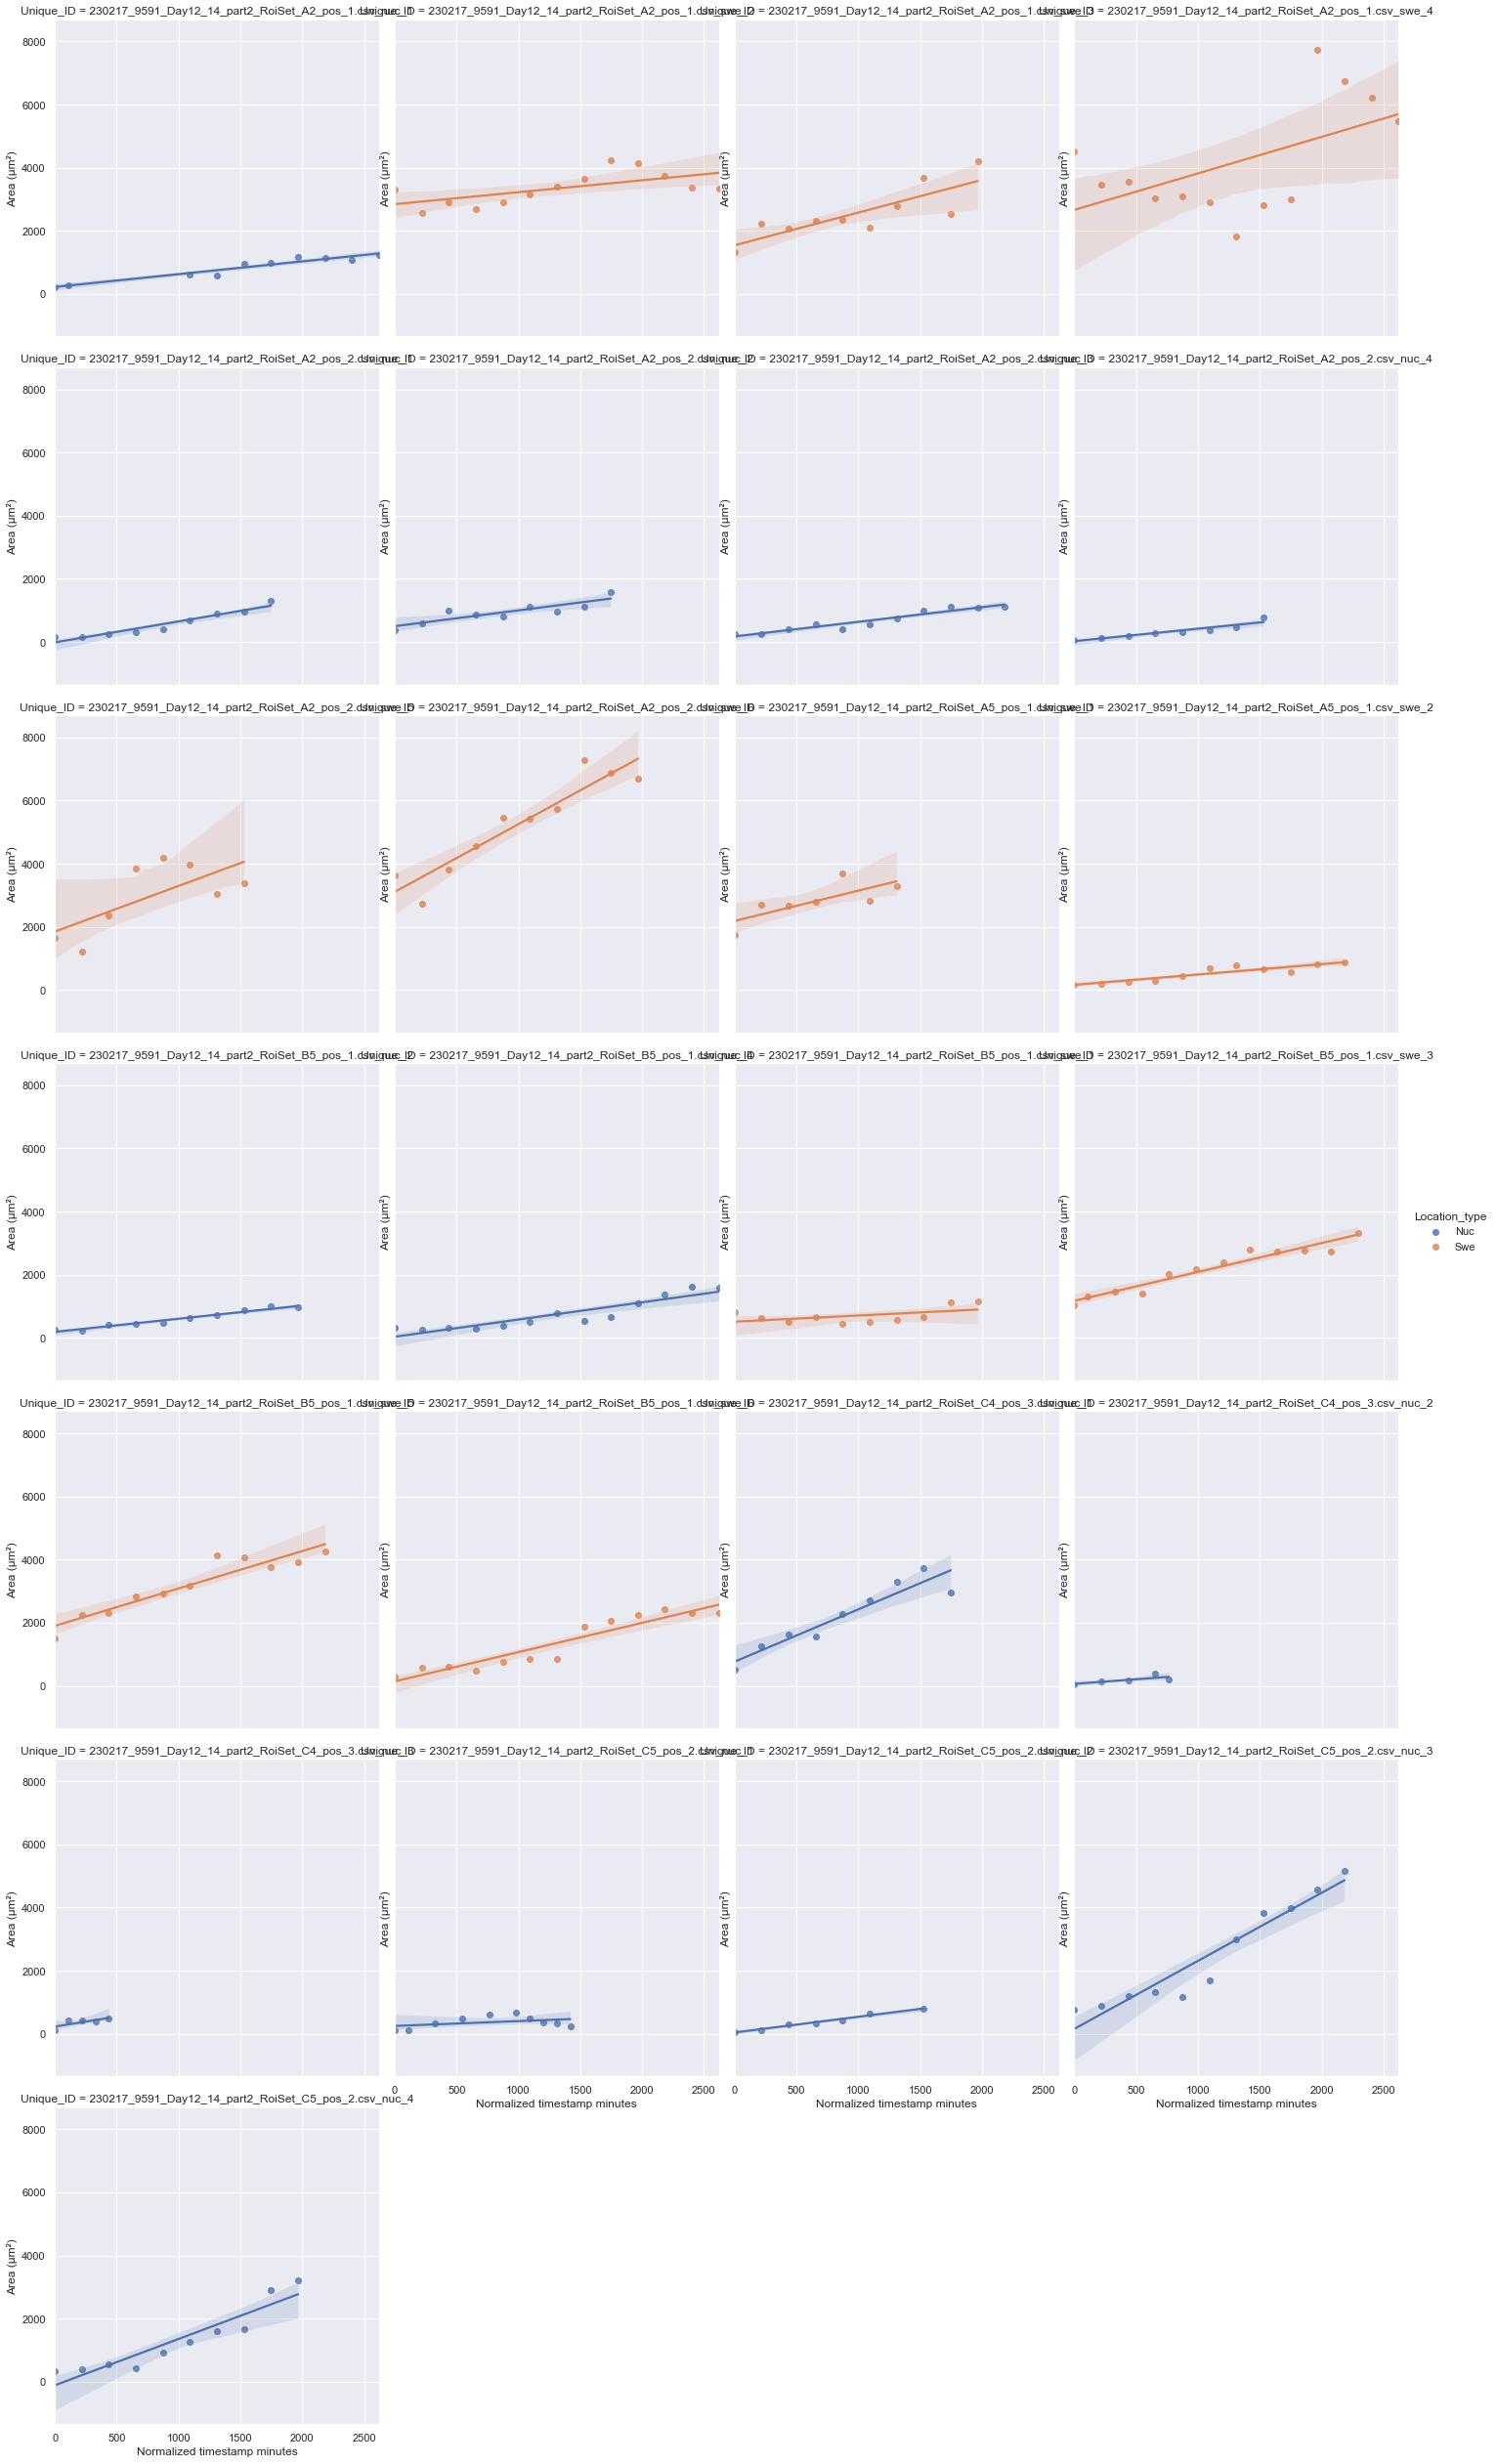

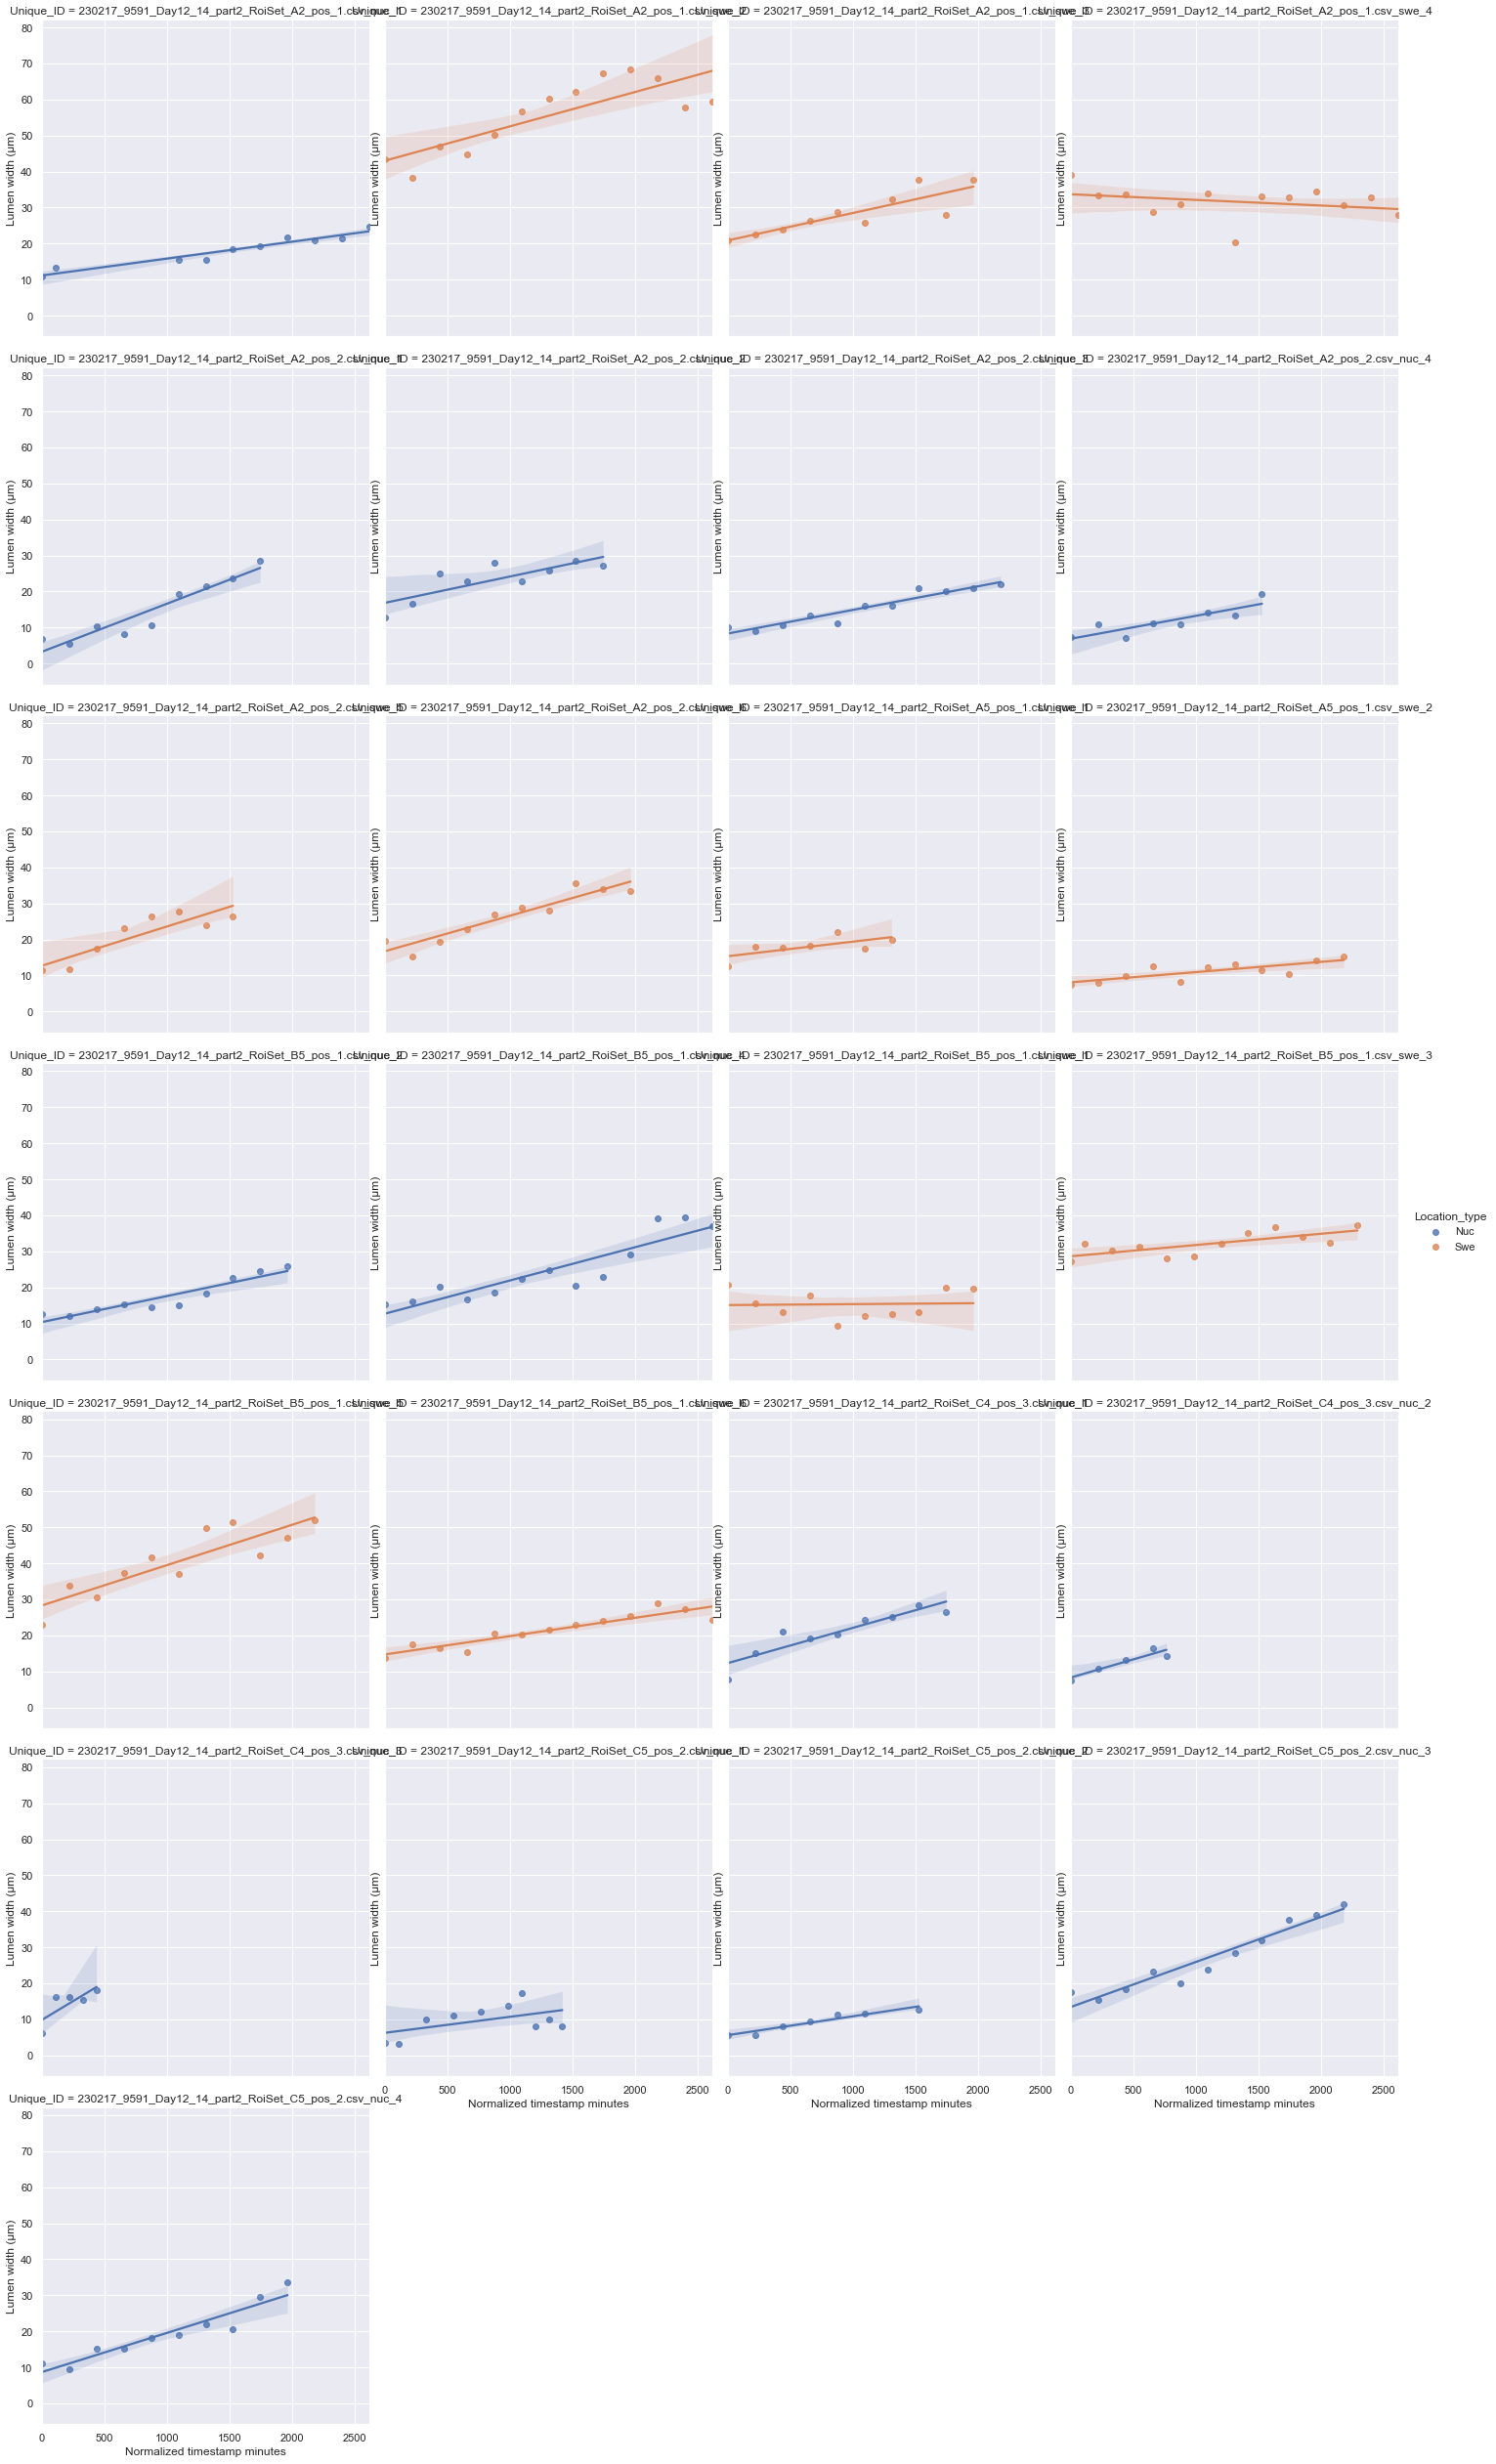

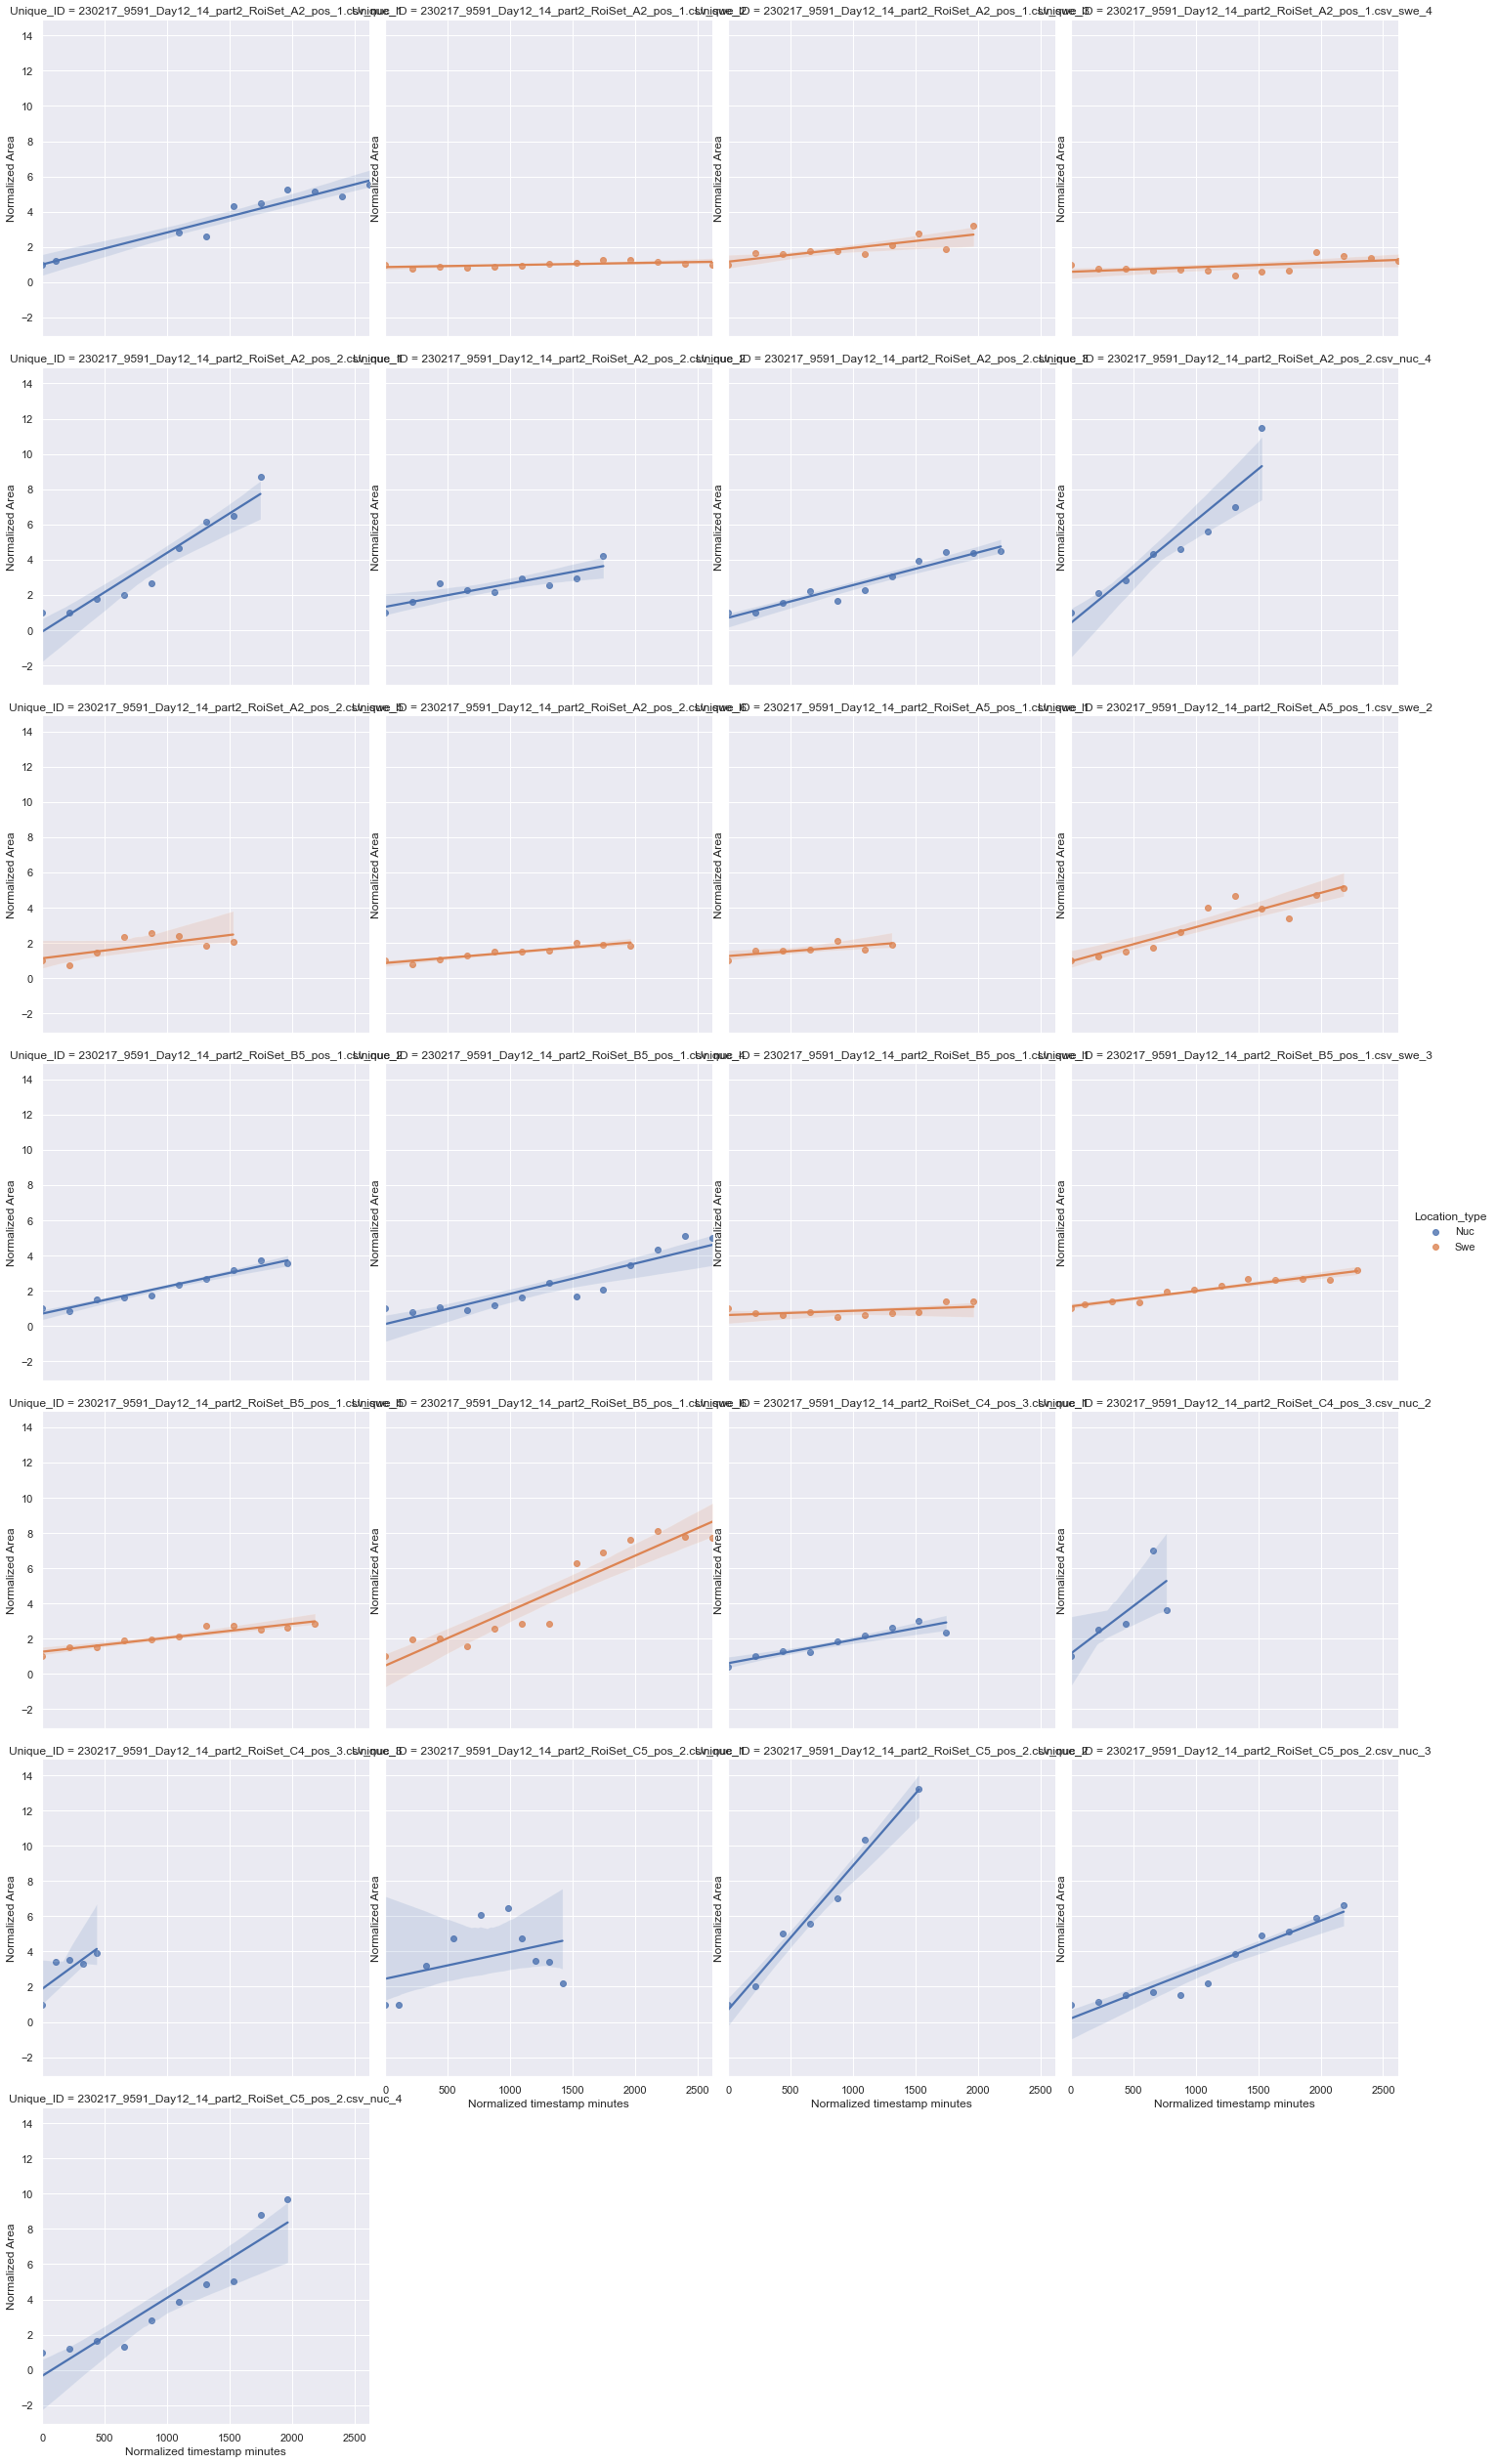

In [9]:
g = sns.lmplot(x="Normalized timestamp minutes", y="Area",
            col="Unique_ID",
            hue="Location_type",
            col_wrap=4,
            data=start_frame_normalized_df_230217)
plt.ylabel("Area (µm²)")
for ax in g.axes.flat:
    ax.set_ylabel("Area (µm²)")
    

g = sns.lmplot(x="Normalized timestamp minutes", y="Minor",
            col="Unique_ID",
            hue="Location_type",
            col_wrap=4,
            data=start_frame_normalized_df_230217)
plt.ylabel("Lumen width (µm)")
for ax in g.axes.flat:
    ax.set_ylabel("Lumen width (µm)")
    
    
g = sns.lmplot(x="Normalized timestamp minutes", y="Normalized Area",
            col="Unique_ID",
            hue="Location_type",
            col_wrap=4,
            data=start_frame_normalized_df_230217)
plt.ylabel("Normalized Area")
for ax in g.axes.flat:
    ax.set_ylabel("Normalized Area")

## We can compute the swelling rate using a linear regression - In the cell below while still keeping the tracks that have a fusion event in them.

In [10]:
## We compute the fits separately for the lumens labelled nuc and swe

lumen_type = ["Nuc", "Swe"]
slope_df_list = []
for lumen_type in ["Nuc", "Swe"]:
    slope_df = compute_linear_slope(start_frame_normalized_df_230217.loc[start_frame_normalized_df_230217["Location_type"] == lumen_type],
                                   "Normalized timestamp minutes", "Area", False)
    slope_df_list.append(slope_df)
    
# Separate the df for further separate use

nuc_slope_df = slope_df_list[0]
swe_slope_df = slope_df_list[1]
    
# Print some summary statistics about the dataframe
print("Nucleating (Nuc) lumen summary:")
print(nuc_slope_df.describe())
print("\n Swelling (Swe) lumen summary:")
print(swe_slope_df.describe())

# We also compute the slopes of both df together

full_slope_df = compute_linear_slope(start_frame_normalized_df_230217, "Normalized timestamp minutes", "Area", False)
print("\n Both lumen types (Nuc and Swe) summary:")
print(full_slope_df.describe())


# Reporting here the counts for nuc only and swe only 
lumen_type = ["Nuc", "Swe"]
for lumen_type in ["Nuc", "Swe"]:
    print("For the {} lumen type".format(lumen_type))
    print("This is the number of individual organoids measured : ")
    print(len(start_frame_normalized_df_230217["File_label"].loc[start_frame_normalized_df_230217["Location_type"] == lumen_type].unique()))
    print("This is the number of individual lumens measured : ")                               
    print(len(start_frame_normalized_df_230217["Unique_ID"].loc[start_frame_normalized_df_230217["Location_type"] == lumen_type].unique()))
    print("-"*50)





Nucleating (Nuc) lumen summary:
           Slope   Intercept
count  14.000000   14.000000
mean    0.731563  181.003772
std     0.588523  224.036025
min     0.153897 -111.355636
25%     0.408145   37.382459
50%     0.499141  165.773636
75%     0.656477  227.420791
max     2.155926  764.480889

 Swelling (Swe) lumen summary:
           Slope    Intercept
count  11.000000    11.000000
mean    0.970445  1643.697728
std     0.553220  1048.395428
min     0.195252   140.697143
25%     0.647046   843.224874
50%     0.960483  1848.296667
75%     1.170879  2424.657857
max     2.145329  3104.560727

 Both lumen types (Nuc and Swe) summary:
           Slope    Intercept
count  25.000000    25.000000
mean    0.836671   824.589112
std     0.574264  1017.001004
min     0.153897  -111.355636
25%     0.405398   140.697143
50%     0.631332   228.488000
75%     1.157306  1543.615273
max     2.155926  3104.560727
For the Nuc lumen type
This is the number of individual organoids measured : 
5
This is the n

## In the cell below, we can remove the part of the tracks that follow a fusion event, thereby keeping our estimation of swelling rates focused on ""single"" lumens

For safety, this function (raise_allowed_flags_if_fusion) performs a sorting by Unique ID and by time, this will reset the index
230217_9591_Day12_14_part2.lif - TileScan 2/B5 Position1:swe_3_t11_fus:z:67/144 t:11/25 - TileScan 2/B5 Position1
Treating  230217_9591_Day12_14_part2_RoiSet_A2_pos_1.csv_nuc_1
Correspond to actual indices:  Int64Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype='int64')
Tap:  Int64Index([4], dtype='int64')
Boop hit_index :  4
Index_list after flagging:  Int64Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype='int64')
**************************************************
At hit_index  4 there is  230217_9591_Day12_14_part2.lif - TileScan 2/A2 Position1:nuc_1_t15_fus:z:35/144 t:15/25 - TileScan 2/A2 Position1
**************************************************
Treating  230217_9591_Day12_14_part2_RoiSet_A2_pos_1.csv_swe_2
Correspond to actual indices:  Int64Index([10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22], dtype='int64')
Treating  230217_9591_Day12_14_part2_RoiSet_A2

C:\Users\Samuel\anaconda3\lib\site-packages\pandas\core\indexing.py:1637: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_block(indexer, value, name)
C:\Users\Samuel\anaconda3\lib\site-packages\pandas\core\indexing.py:1637: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_block(indexer, value, name)
C:\Users\Samuel\anaconda3\lib\site-packages\pandas\core\indexing.py:1637: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-vi

<Figure size 432x288 with 0 Axes>

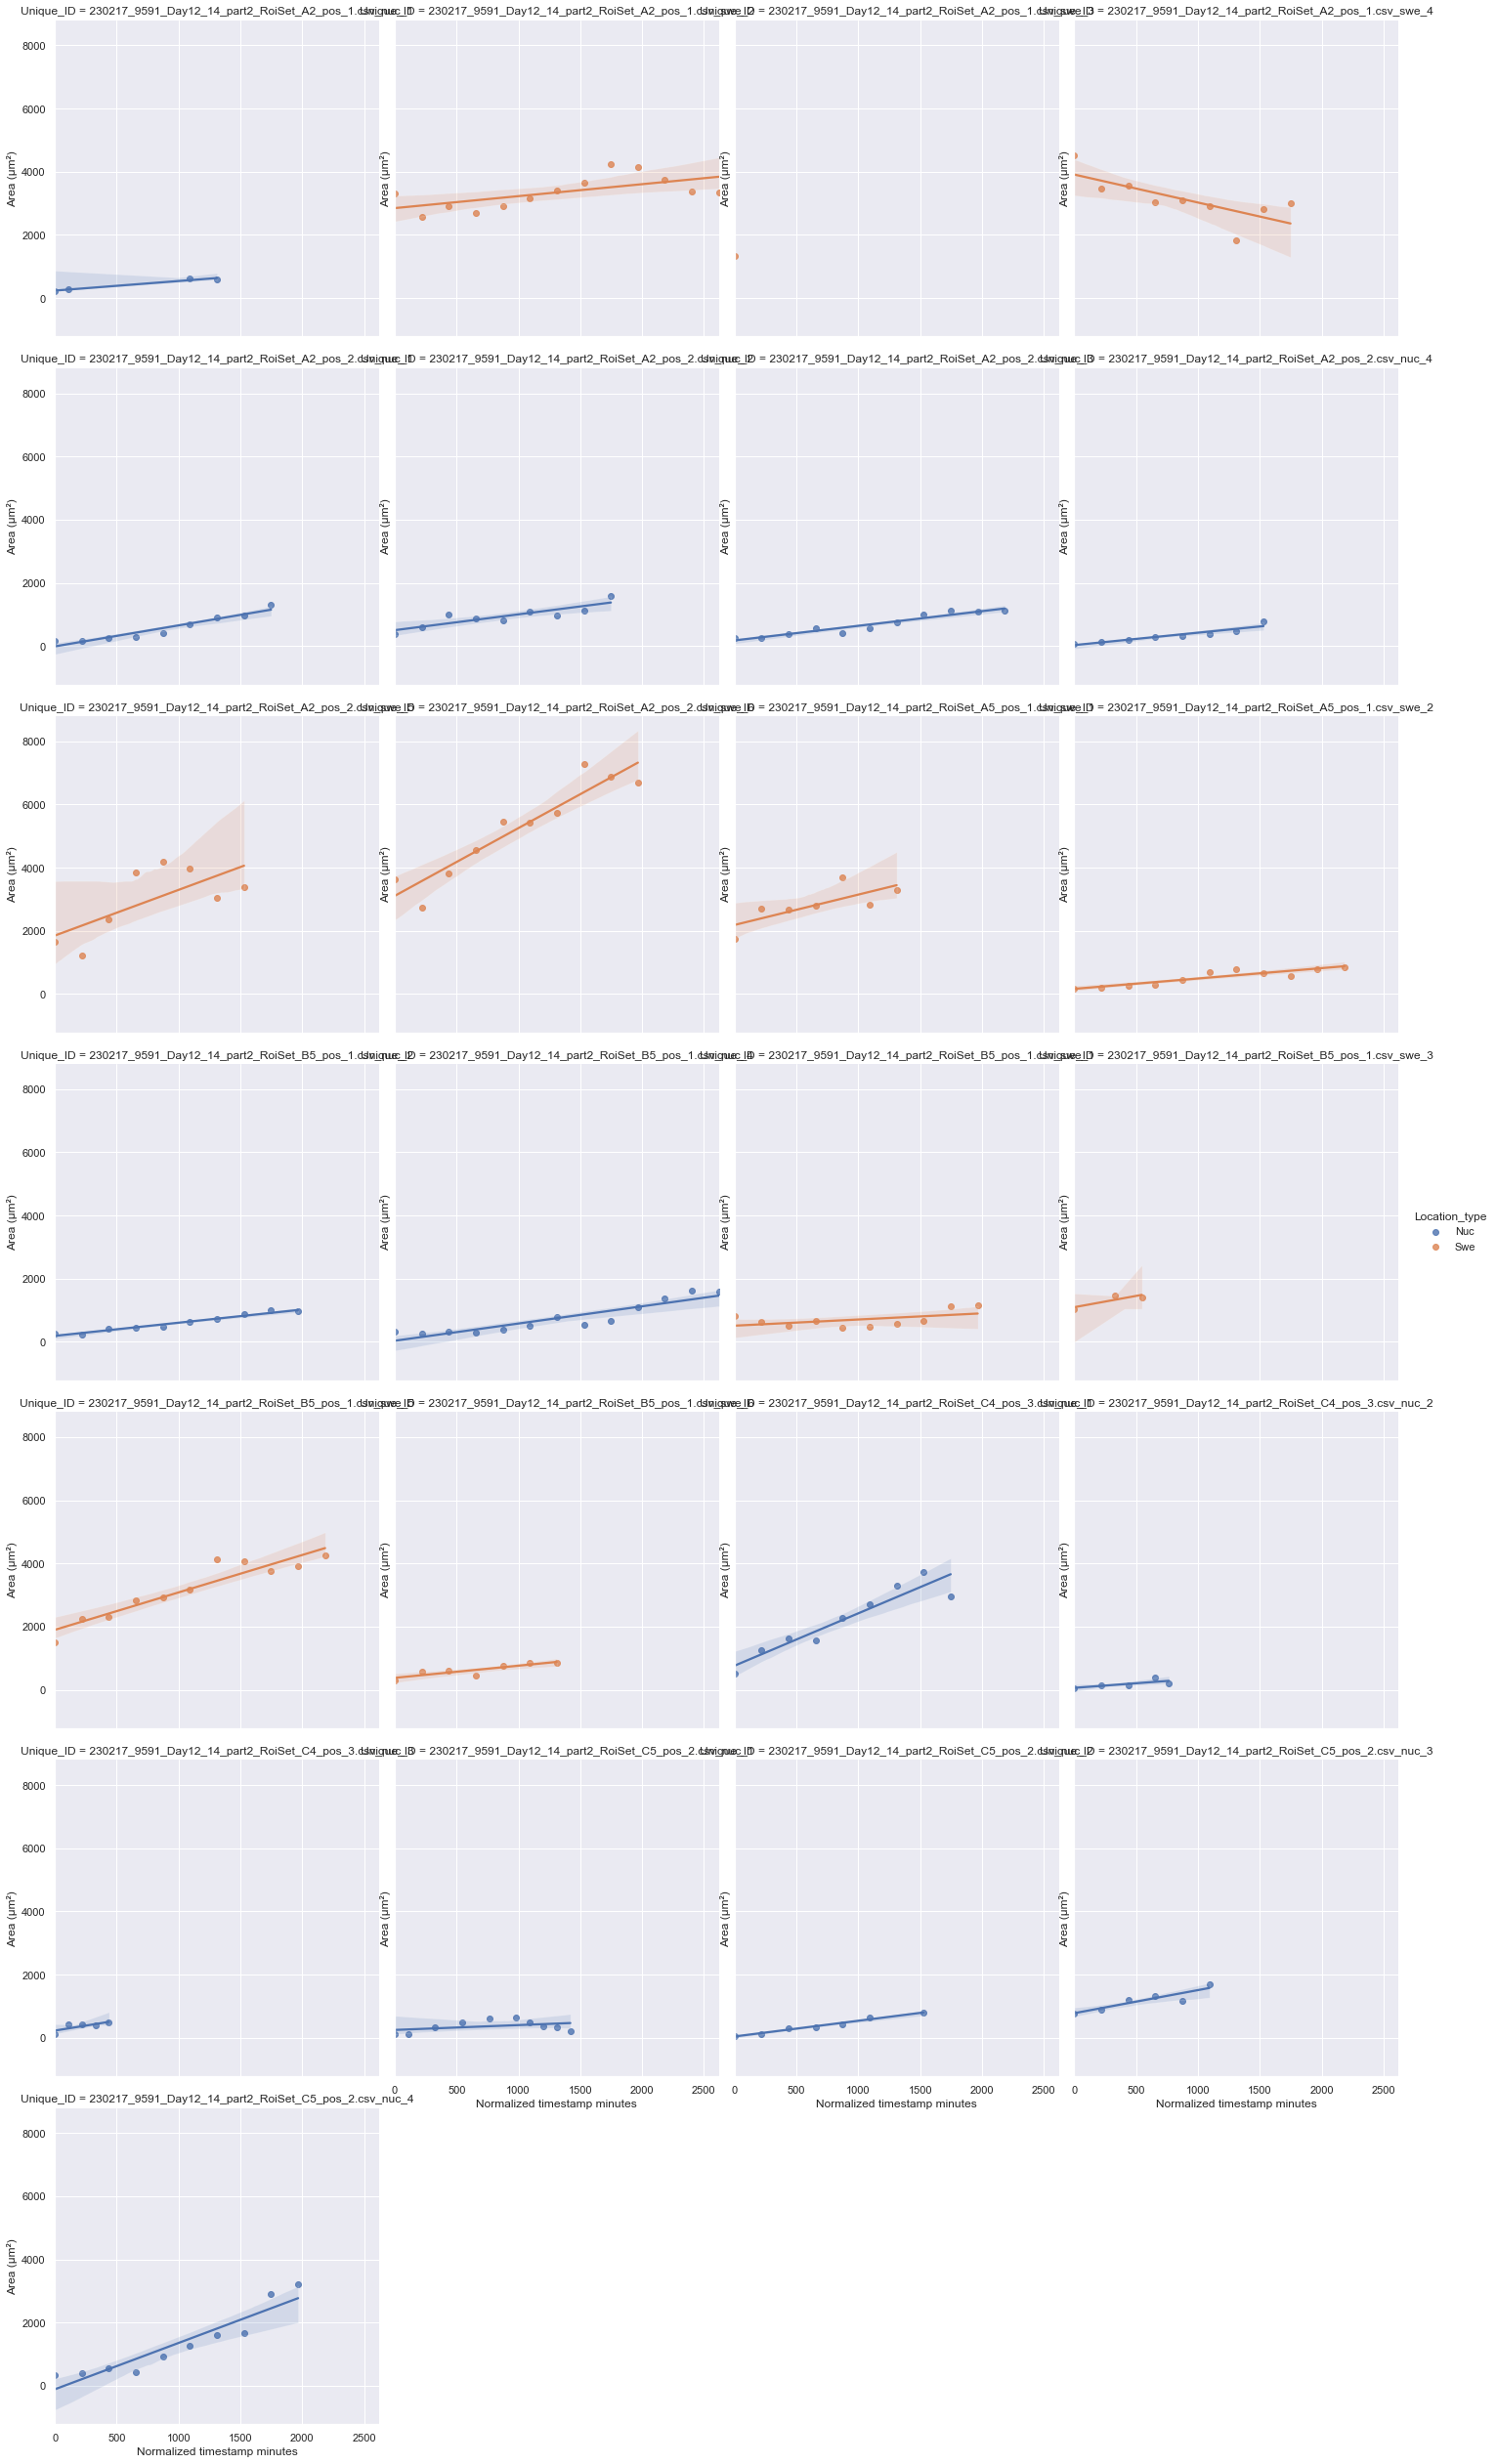

<Figure size 432x288 with 0 Axes>

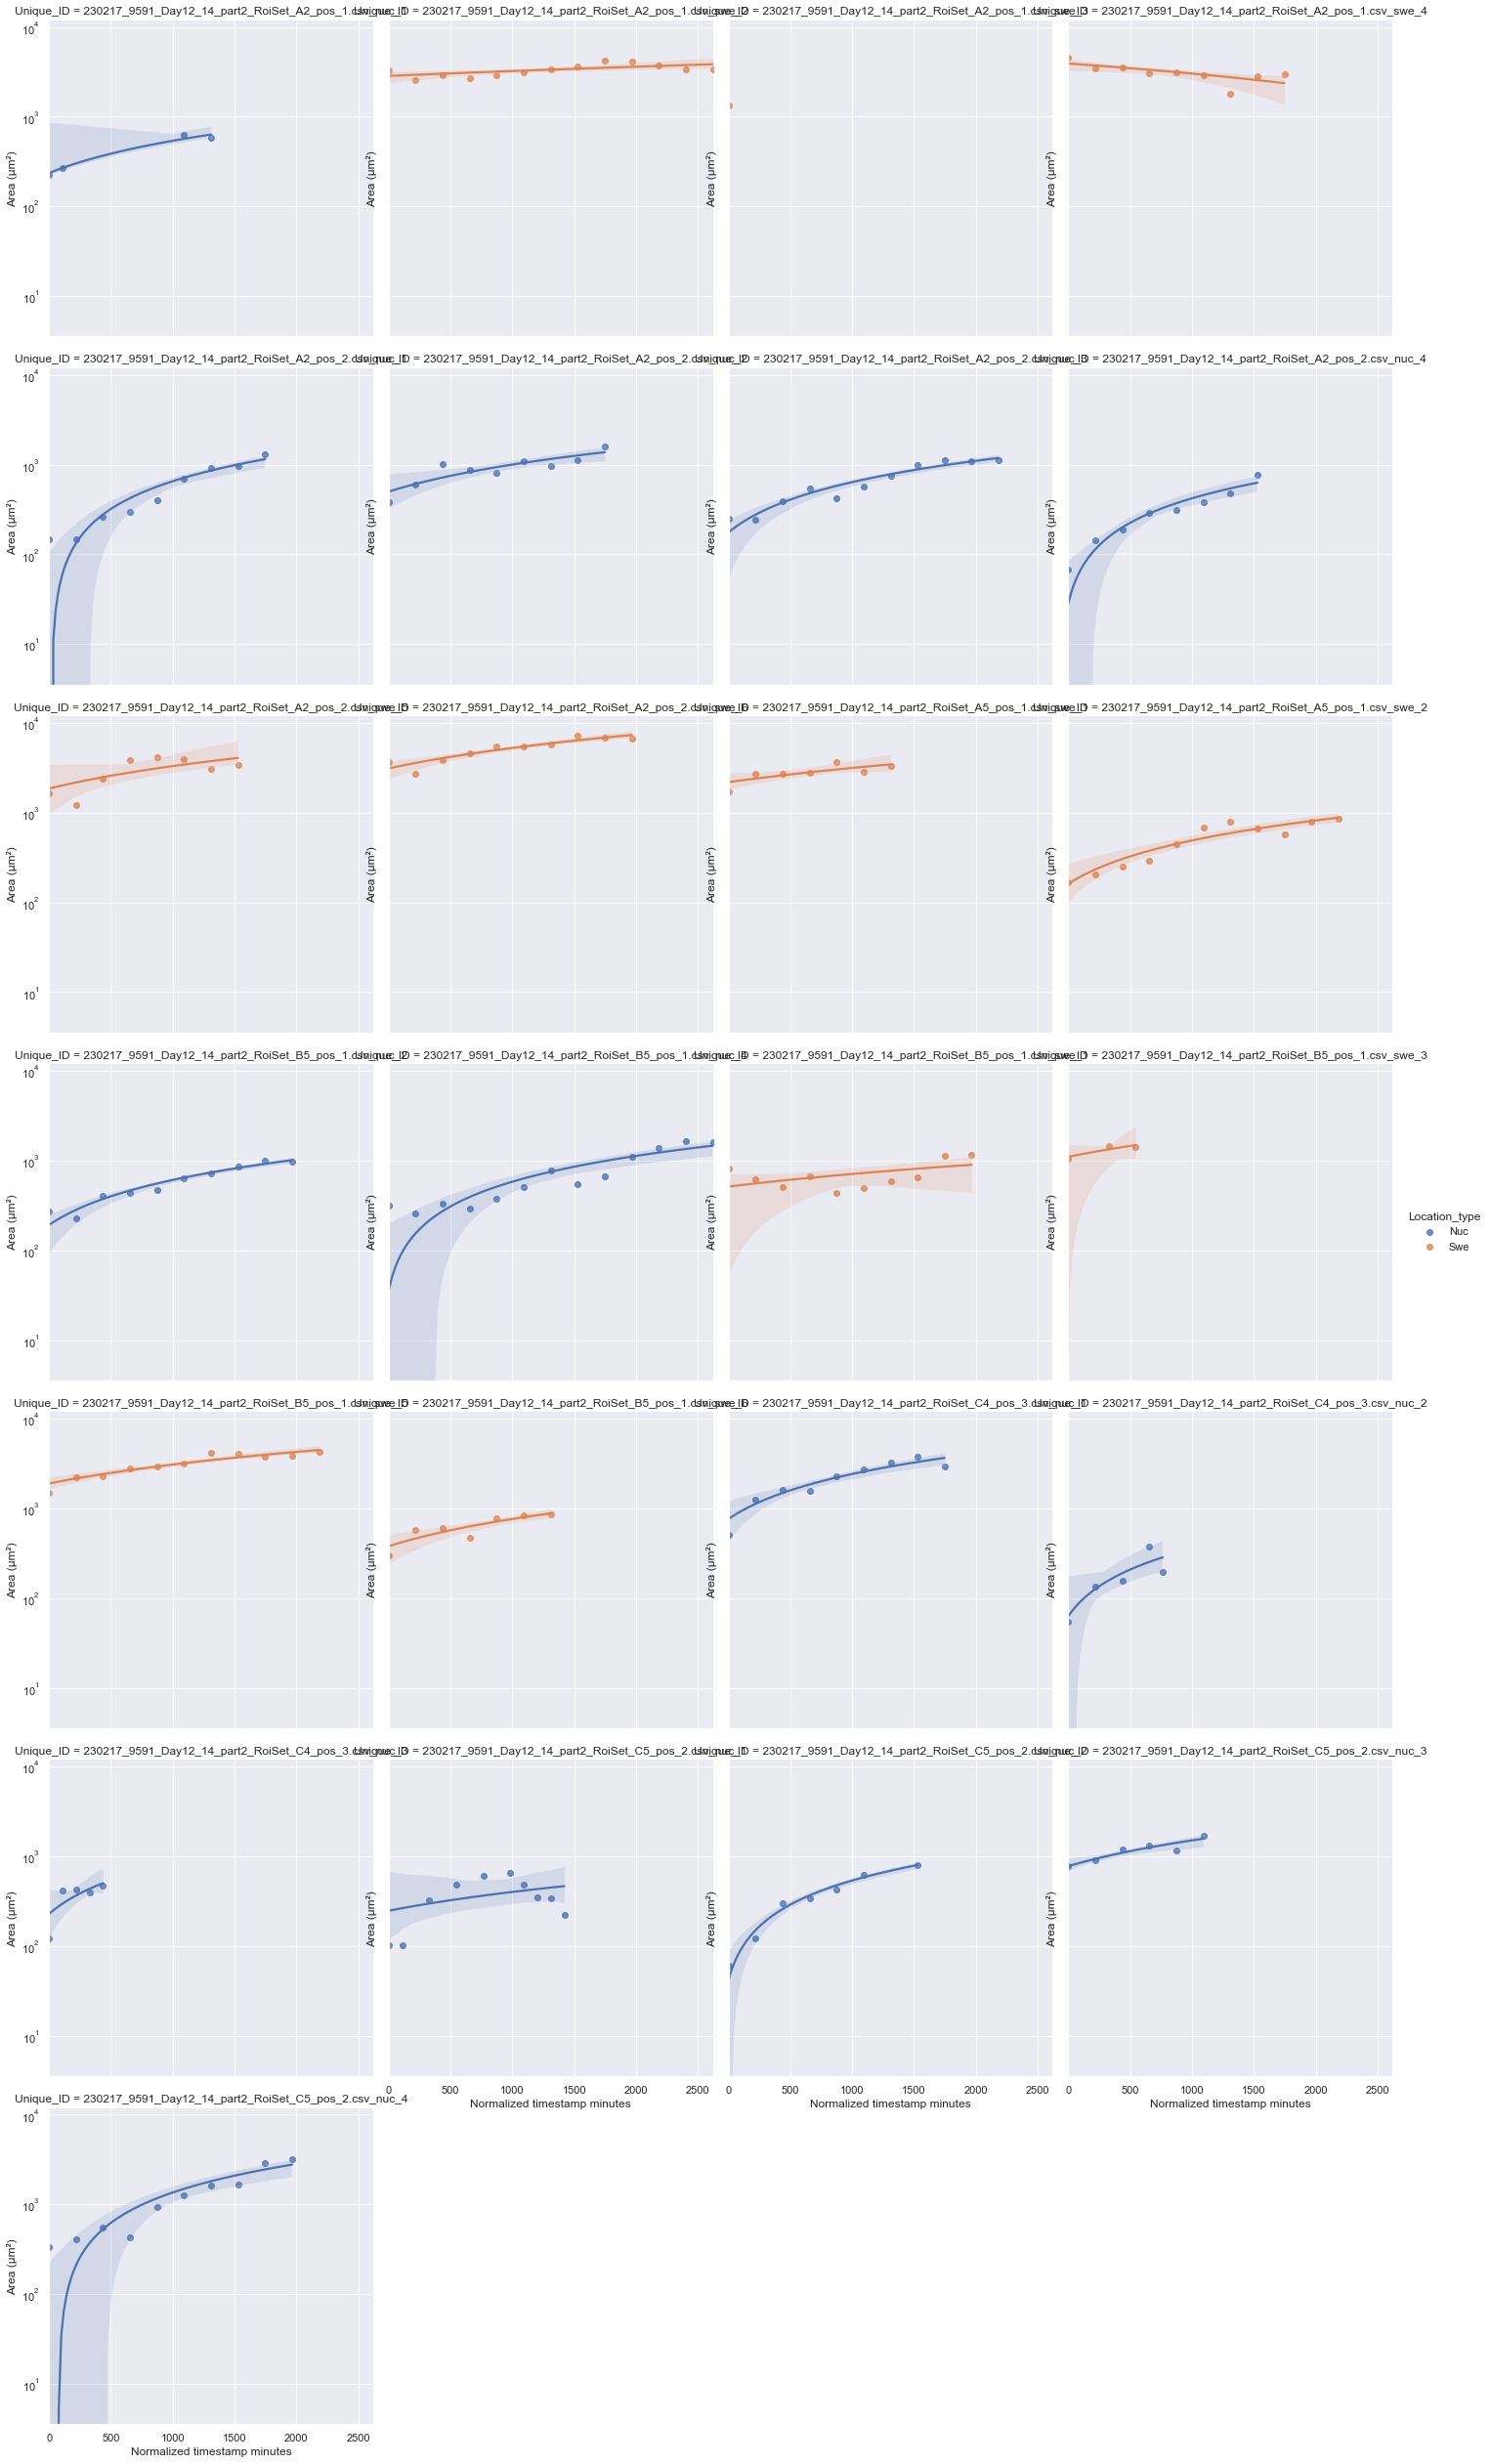

<Figure size 432x288 with 0 Axes>

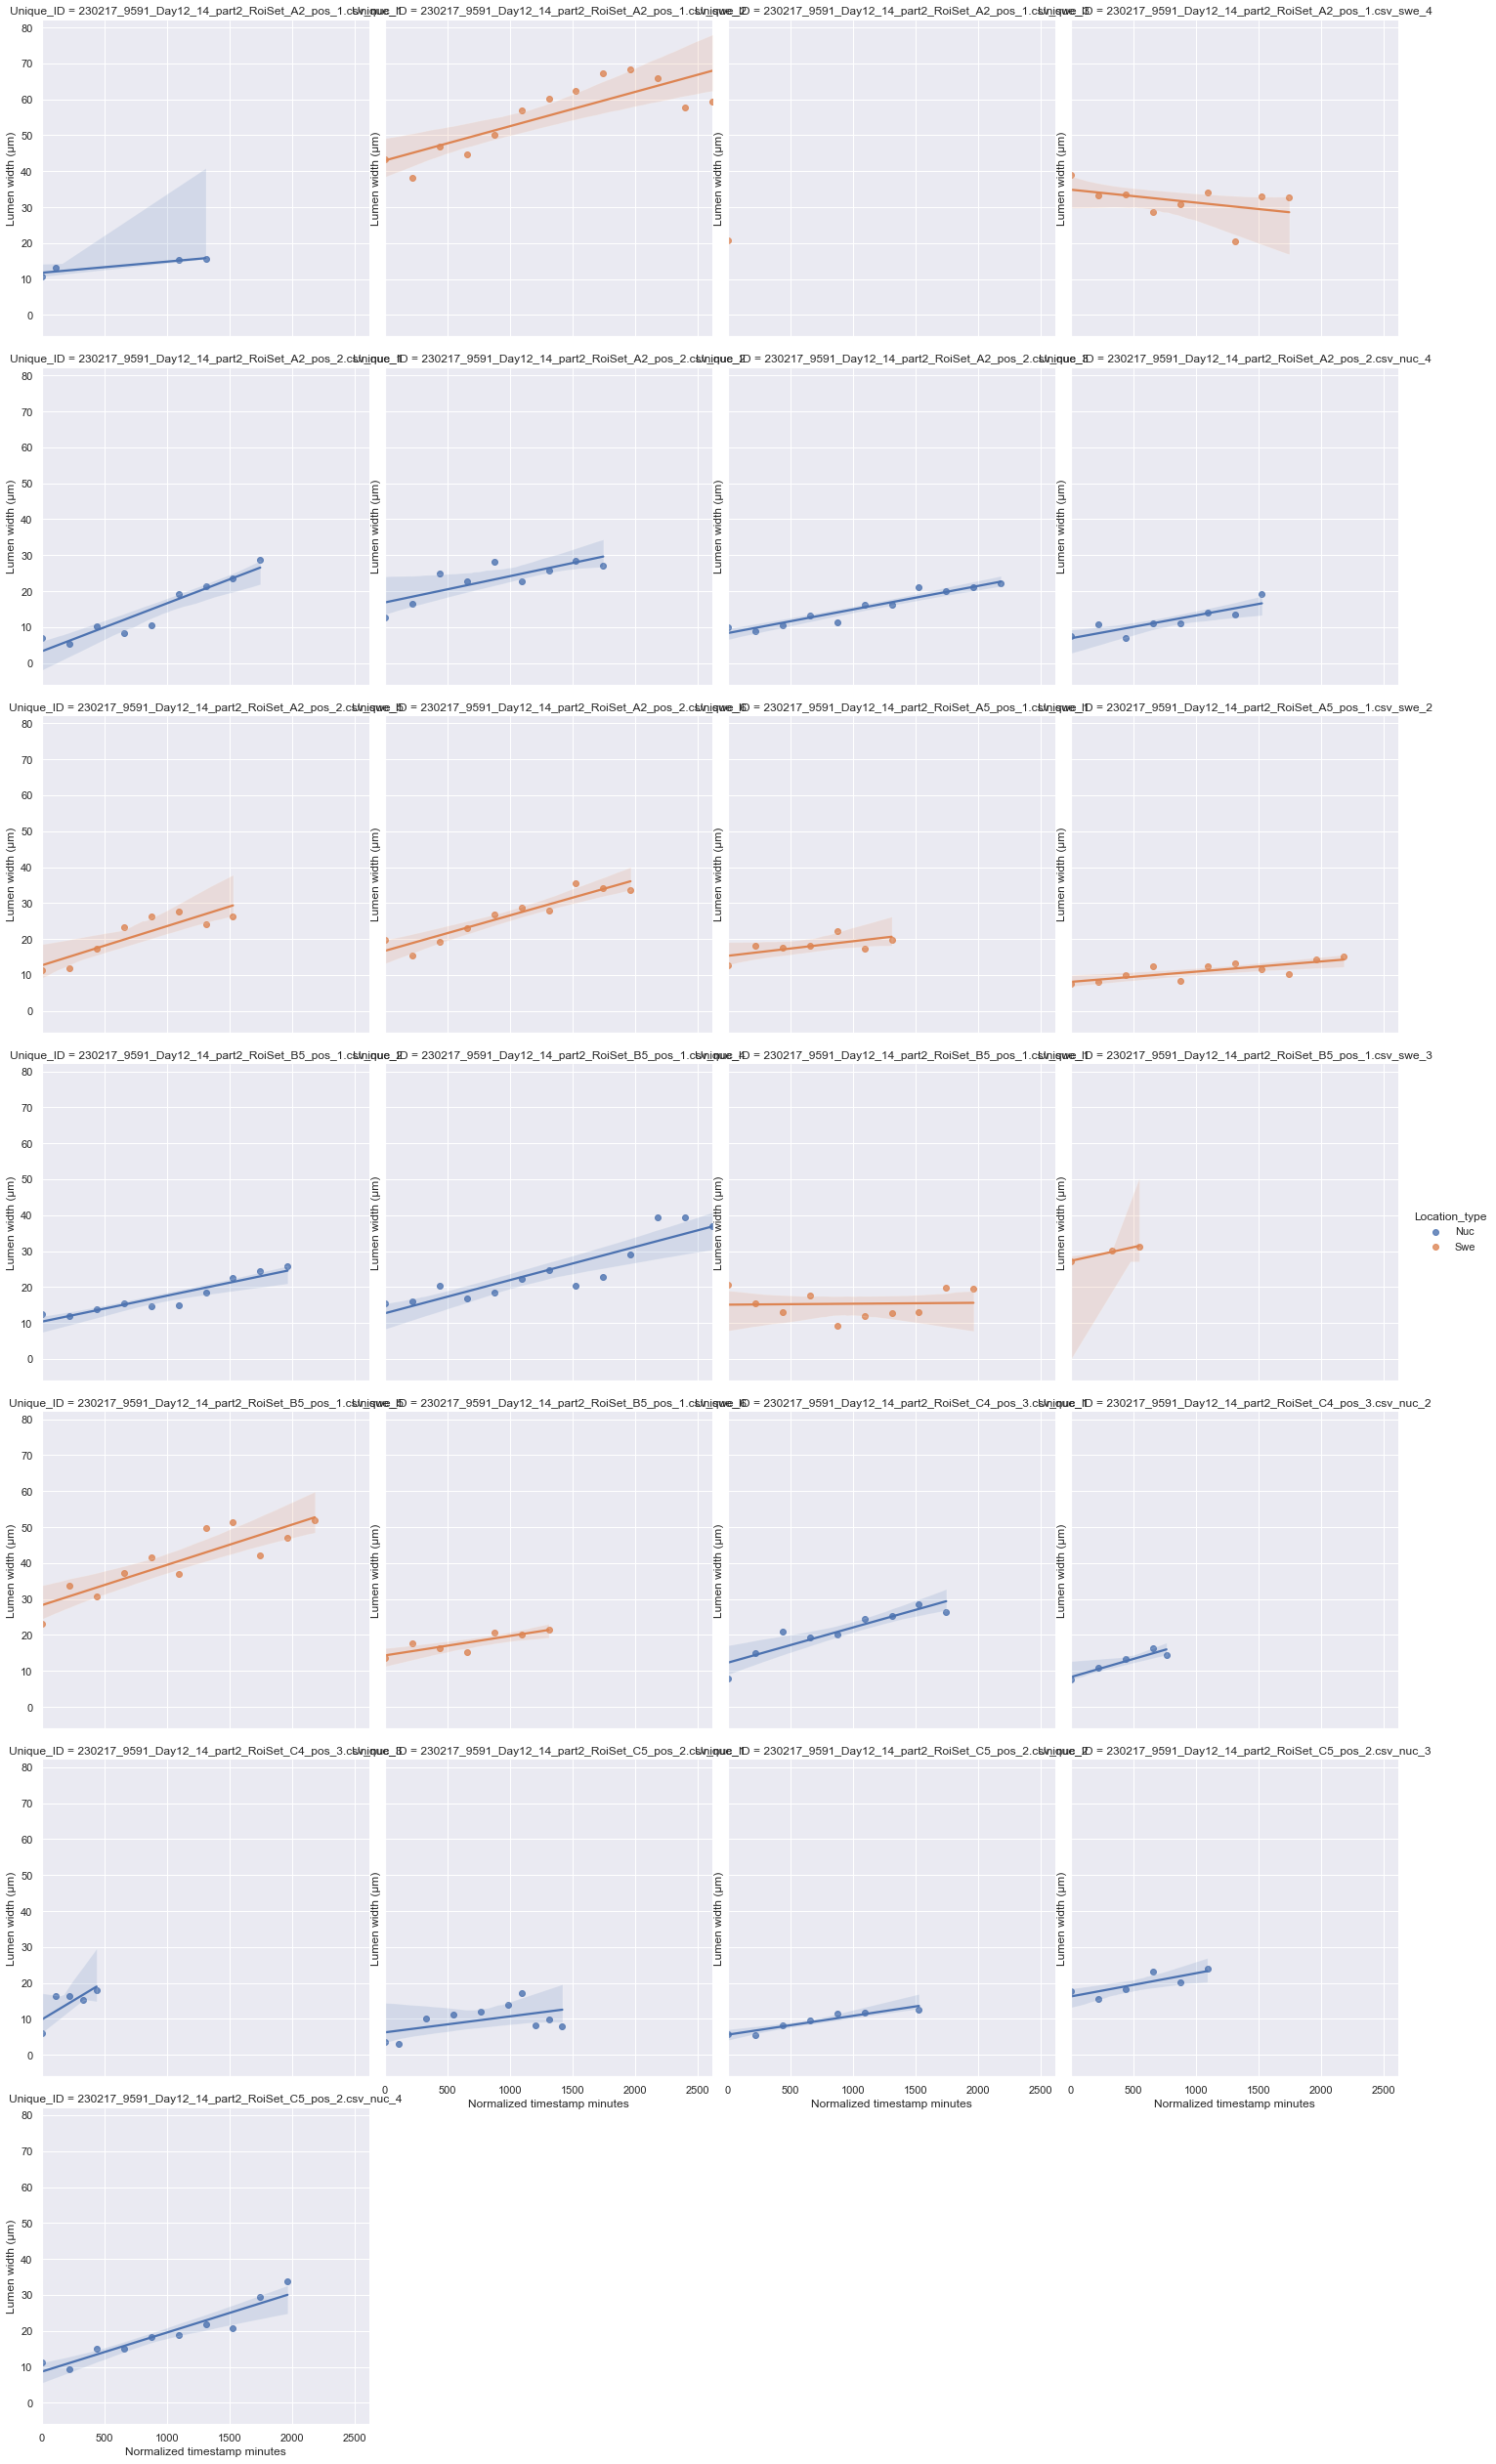

<Figure size 432x288 with 0 Axes>

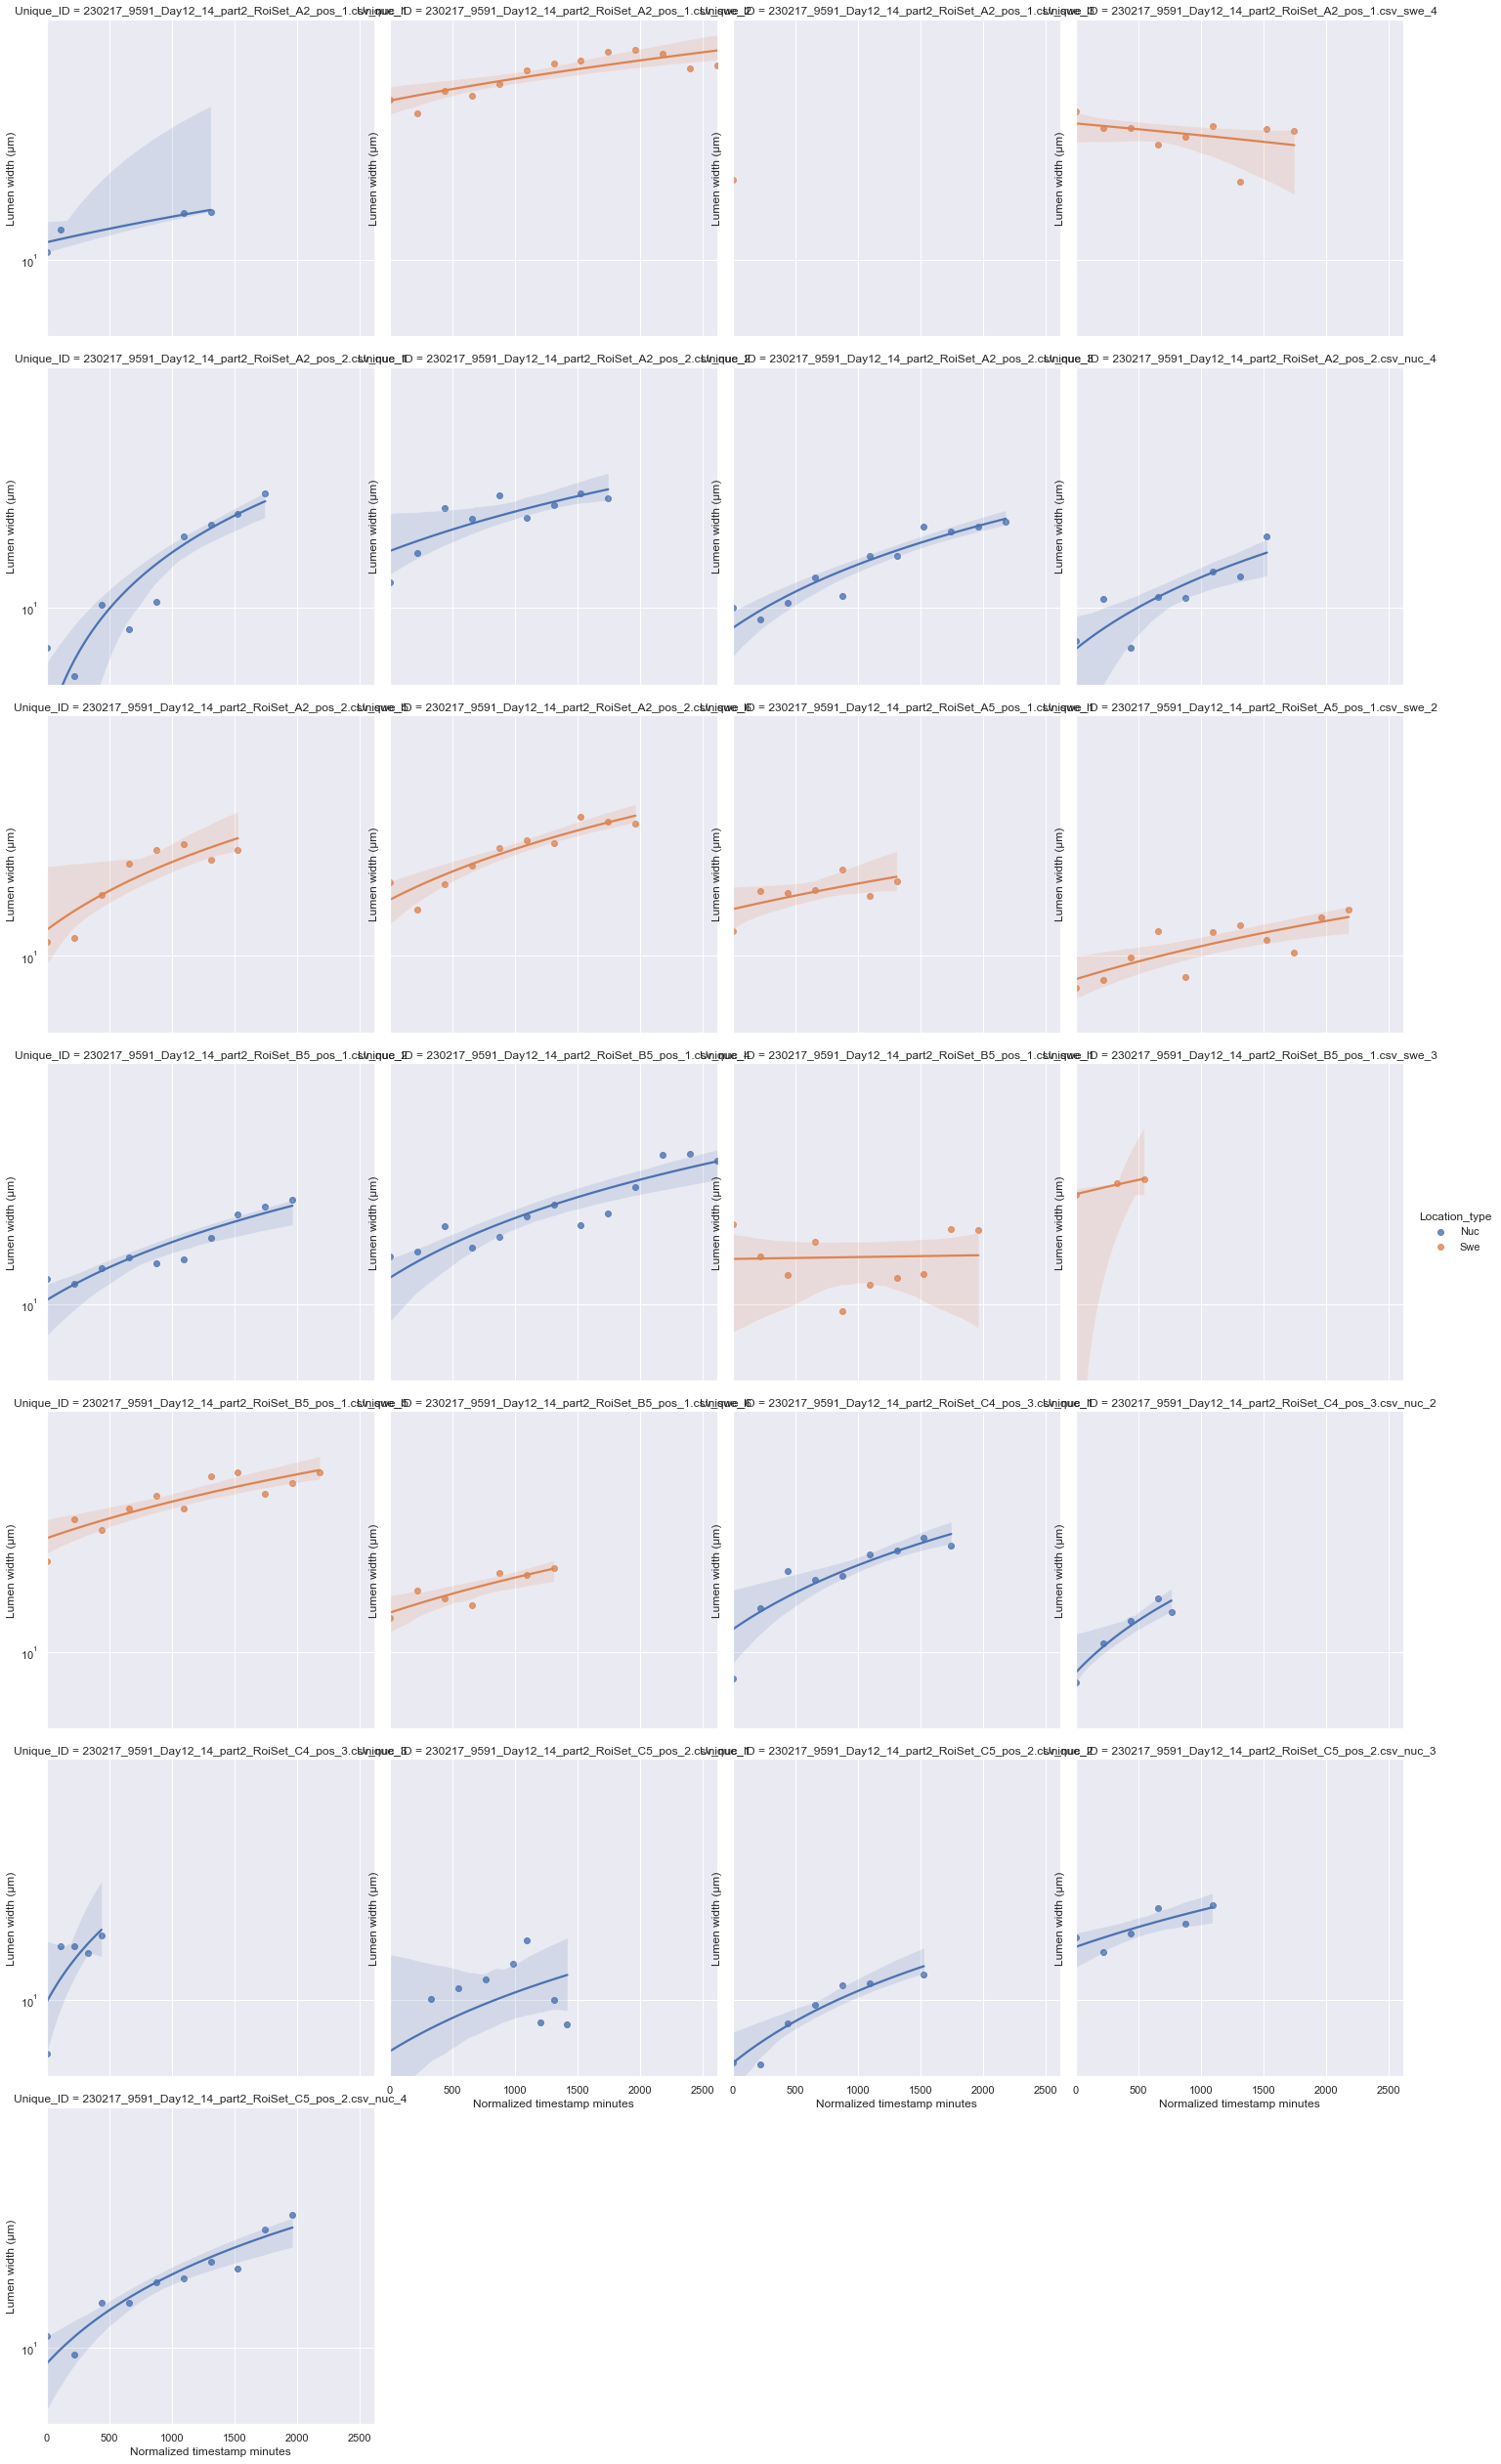

In [11]:
# Fusion events might perturb the rate computing, so we can temporarily remove them from the computation 


start_frame_normalized_df_230217 = raise_allowed_flags_if_fusion(start_frame_normalized_df_230217, disable_all=False)
lumen_type = ["Nuc", "Swe"]
slope_df_no_fus_list = []
for lumen_type in ["Nuc", "Swe"]:
    slope_df = compute_linear_slope(start_frame_normalized_df_230217.loc[(start_frame_normalized_df_230217["Location_type"] == lumen_type) & start_frame_normalized_df_230217["Allowed flags if no/before fusion"] == True],
                                   "Normalized timestamp minutes", "Area", False)
    slope_df_no_fus_list.append(slope_df)

# Separate the df for further separate use

nuc_slope_no_fus_df = slope_df_no_fus_list[0]
swe_slope_no_fus_df = slope_df_no_fus_list[1]
    

# The slope (i.e the cross-sectional swelling rate) is currently computed in Area (µm²) per (normalized) minutes
# We can compute it in Area (µm²) per hour to make it more understandable

nuc_slope_no_fus_df["Cross-sectional area swelling rate (µm²/hour)"] = nuc_slope_no_fus_df["Slope"] * 60
swe_slope_no_fus_df["Cross-sectional area swelling rate (µm²/hour)"] = swe_slope_no_fus_df["Slope"] * 60
    
    
# We can also compute it in µm/day since the minor axis swelling rate is not immediately large

nuc_slope_no_fus_df["Cross-sectional area swelling rate (µm²/day)"] = nuc_slope_no_fus_df["Slope"] * 60 * 24
swe_slope_no_fus_df["Cross-sectional area swelling rate (µm²/day)"] = swe_slope_no_fus_df["Slope"] * 60 * 24
    
    
# Print some summary statistics about the dataframe
print("Nucleating (Nuc) lumen summary:")
print(nuc_slope_no_fus_df.describe())
print("\n Swelling (Swe) lumen summary:")
print(swe_slope_no_fus_df.describe())


removed_post_fusion_event_mask = start_frame_normalized_df_230217["Allowed flags if no/before fusion"] == True

# Plot the linear regressions for the Area with the post-fusion recordings disabled
plt.figure()
g = sns.lmplot(x="Normalized timestamp minutes", y="Area",
            col="Unique_ID",
            hue="Location_type",
            col_wrap=4,
            data=start_frame_normalized_df_230217.loc[removed_post_fusion_event_mask])
plt.ylabel("Area (µm²)")
for ax in g.axes.flat:
    ax.set_ylabel("Area (µm²)")
plt.show()

# Plot the linear regressions for the Area with a semilog y axis
plt.figure()
g = sns.lmplot(x="Normalized timestamp minutes", y="Area",
            col="Unique_ID",
            hue="Location_type",
            col_wrap=4,
            data=start_frame_normalized_df_230217.loc[removed_post_fusion_event_mask])
plt.semilogy()
plt.ylabel("Area (µm²)")
for ax in g.axes.flat:
    ax.set_ylabel("Area (µm²)")
plt.show()


# Plot the linear regressions for the Minor axis (i.e. the lumen width) with the post-fusion recordings disabled
plt.figure()
g = sns.lmplot(x="Normalized timestamp minutes", y="Minor",
            col="Unique_ID",
            hue="Location_type",
            col_wrap=4,
            data=start_frame_normalized_df_230217.loc[removed_post_fusion_event_mask])
plt.ylabel("Lumen width (µm)")
for ax in g.axes.flat:
    ax.set_ylabel("Lumen width (µm)")
plt.show()


# Plot the linear regressions for the Minor axis (i.e. the lumen width) with a semilog y-axis
plt.figure()
g = sns.lmplot(x="Normalized timestamp minutes", y="Minor",
            col="Unique_ID",
            hue="Location_type",
            col_wrap=4,
            data=start_frame_normalized_df_230217.loc[removed_post_fusion_event_mask])
plt.semilogy()
plt.ylabel("Lumen width (µm)")
for ax in g.axes.flat:
    ax.set_ylabel("Lumen width (µm)")
plt.show()



# Plotting section for the paper

## Difference between "Nuc" and "Swe" lumens: Nuc are lumens that we can identify from their nucleation point onwards, whereas "Swe" lumens are lumens that are already formed when we start measuring them.

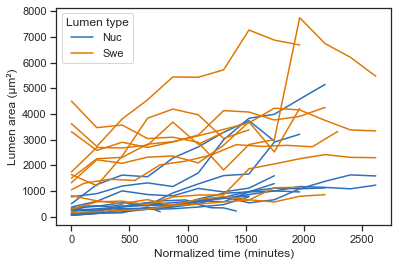

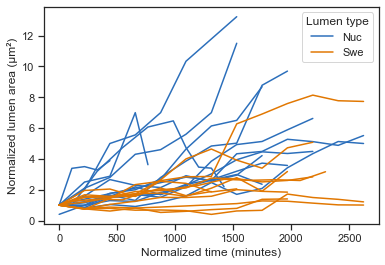

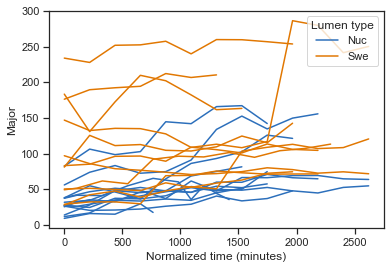

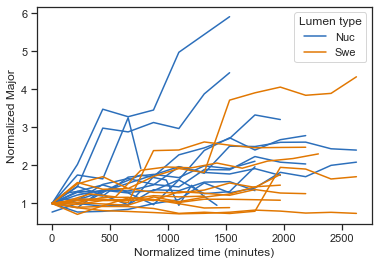

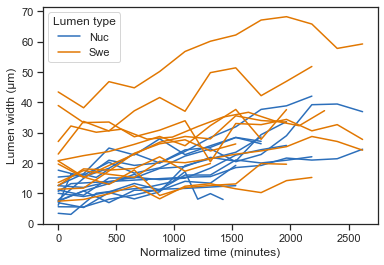

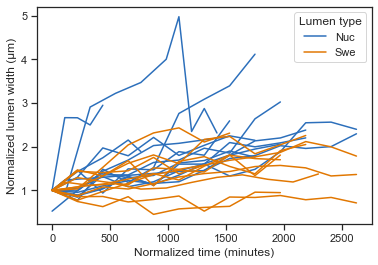

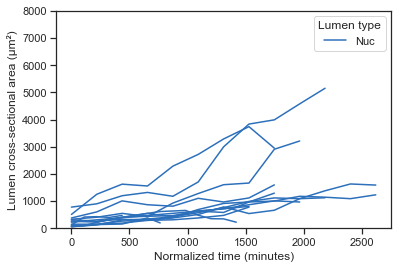

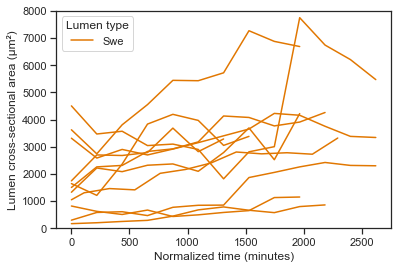

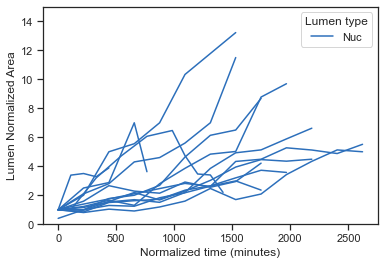

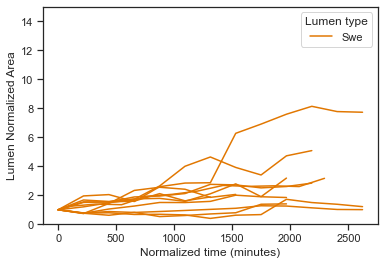

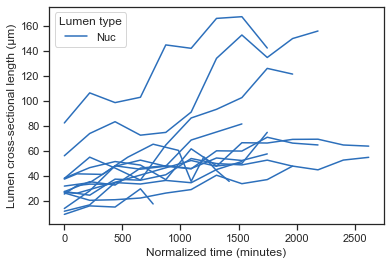

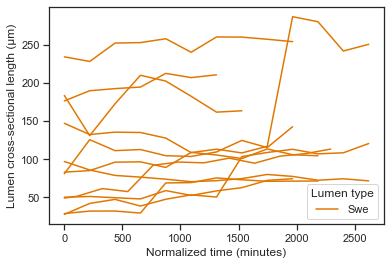

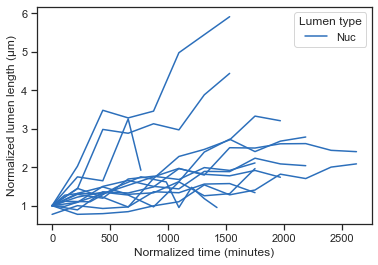

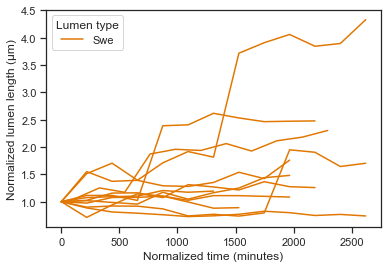

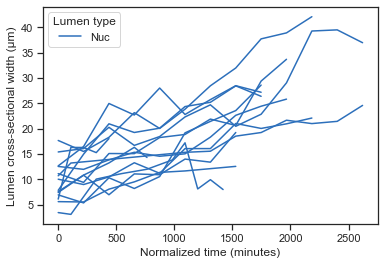

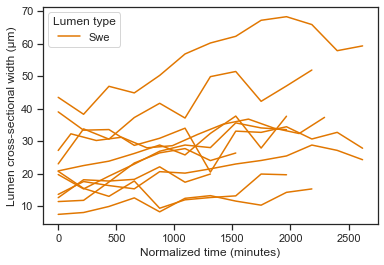

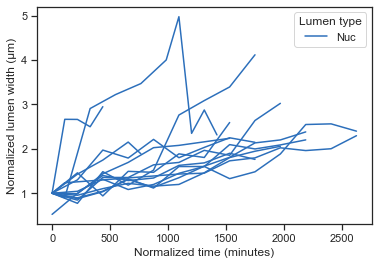

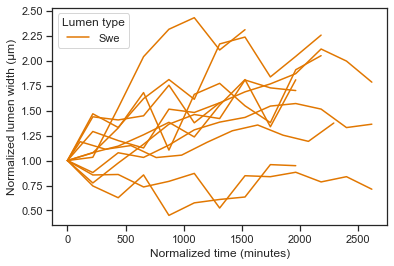

In [12]:
# Plotting cell for the paper

param_list = ["Area", "Normalized Area", "Major", "Normalized Major", "Minor", "Normalized Minor"]
lumen_type_list = ["Nuc", "Swe"]
palette_lumen_type = ["xkcd:medium blue", "xkcd:pumpkin"]
#palette_lumen_type = ["xkcd:black", "xkcd:red"]
#palette_lumen_type = ["#1b9e77", "#7570b3" ]
#palette_lumen_type = ["tab:cyan", "tab:red"]

graphs_folder = "./Graphs/"

with sns.axes_style("ticks"):
    ## Every lumen together
    for param in param_list:
        plt.figure()
        param_savename = param
        g = sns.lineplot(x="Normalized timestamp minutes", y=param, 
                         units="Unique_ID",
                         estimator=None,
                         hue="Location_type",
#                         marker="o",
                         alpha=1,
#                         style="Location_type",
                         palette=palette_lumen_type,
                        data=start_frame_normalized_df_230217)
        if param=="Area":
            plt.ylabel("Lumen area (µm²)")
        if param=="Normalized Area":
            plt.ylabel("Normalized lumen area (µm²)")
        if param=="Minor":
            plt.ylabel("Lumen width (µm)")
        if param=="Normalized Minor":
            plt.ylabel("Normalized lumen width (µm)")
        plt.legend(title='Lumen type')
        plt.xlabel("Normalized time (minutes)")
        savefigure(graphs_folder, param_savename+"_"+"together")
    
   

    ## Nuc and swe separated
    for param in param_list:
        param_savename = param
        for l_type, palette in zip(lumen_type_list,palette_lumen_type):
            plt.figure()
            g = sns.lineplot(x="Normalized timestamp minutes", y=param, 
                         units="Unique_ID",
                         estimator=None,
                         hue="Location_type",
#                         color=palette,
                         palette=[palette],
#                         marker="o",
                        data=start_frame_normalized_df_230217.loc[start_frame_normalized_df_230217["Location_type"]==l_type])
            if param=="Area":
                plt.ylabel("Lumen cross-sectional area (µm²)")
                ax = plt.gca()
                ax.set_ylim([0, 8000]) # TODO: Value hardcoded for now, replace at some point
                param_savename = "area"
            if param=="Normalized Area":
                plt.ylabel("Lumen {}".format(param)) 
                ax = plt.gca()
                ax.set_ylim([0, 15]) # TODO: Value hardcoded for now, replace at some point               
                param_savename = "normalized_area"
            if param=="Minor":
                plt.ylabel("Lumen cross-sectional width (µm)")
            if param=="Normalized Minor":
                plt.ylabel("Normalized lumen width (µm)")
            if param=="Major":
                plt.ylabel("Lumen cross-sectional length (µm)")
            if param=="Normalized Major":
                plt.ylabel("Normalized lumen length (µm)")
#            ax = plt.gca()
#            ax.legend(title='Lumen type', labels=l_type)
            plt.legend(title='Lumen type')
            plt.xlabel("Normalized time (minutes)")
            savefigure(graphs_folder, param_savename+"_"+l_type)
    


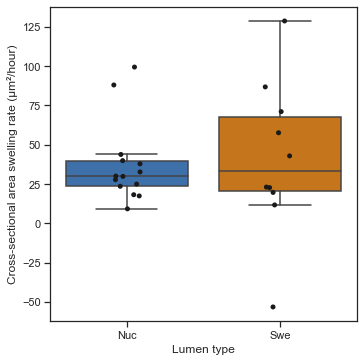

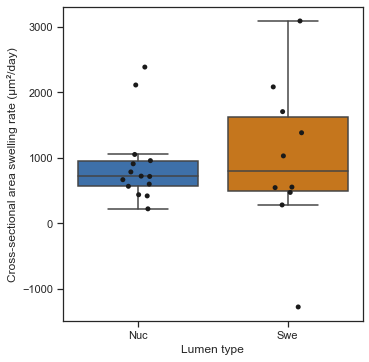

In [13]:
# Plotting the mean swelling rate with exclusion of fusion events

slope_no_fus_df = pd.concat([nuc_slope_no_fus_df,swe_slope_no_fus_df])



palette_lumen_type = ["xkcd:medium blue", "xkcd:pumpkin"]

with sns.axes_style("ticks"):
    # Note that the outliers display is set to false in the boxplot to avoid duplicating points with the stripplot
    g = sns.catplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/hour)", kind="box", 
                    palette=palette_lumen_type,
                    data=slope_no_fus_df,showfliers=False)
    sns.stripplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/hour)",  
                    color="k", 
                    ax=g.ax,
                    alpha=1,
                    data=slope_no_fus_df)
    plt.xlabel("Lumen type")
    sns.despine(top=False,right=False, left=False,bottom=False)
    savefigure(graphs_folder, "swelling_rate_um2_per_hour_together_box")
    
    
with sns.axes_style("ticks"):
    # Note that the outliers display is set to false in the boxplot to avoid duplicating points with the stripplot
    g = sns.catplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/day)", kind="box", 
                    palette=palette_lumen_type,
                    data=slope_no_fus_df,showfliers=False)
    sns.stripplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/day)",  
                    color="k", 
                    ax=g.ax,
                    alpha=1,
                    data=slope_no_fus_df)
    plt.xlabel("Lumen type")
    sns.despine(top=False,right=False, left=False,bottom=False)
    savefigure(graphs_folder, "swelling_rate_um2_per_day_together_box")
    

   

# Create a separate analysis for lumens from "blowup" organoids

## Loading the datasets

In [14]:
"""
Loading the Excel file containing the observations
"""

## Folder to save produced graphs
graphs_folder = "./Graphs/"
print(graphs_folder)
## Loading dataset
measurement_folder = "./blowup_csv/"
print(measurement_folder)

experiment_name_230217 = "230217_9591_Day12_14_part2"
experiment_name_221003 = "221003_9591_Day10_13"

timestep_221003_sec = 4859 # seconds
timestep_221003_min = timestep_221003_sec / 60.0 # minutes



df_blowup_230217 = prepare_nuc_swe_lumen_dataframe(os.path.join(measurement_folder, experiment_name_230217), experiment_name_230217, timestep_230217_min)
df_blowup_230217 = normalize_timestamp_minutes(df_blowup_230217, timestep_230217_min)

df_blowup_221003 = prepare_nuc_swe_lumen_dataframe(os.path.join(measurement_folder, experiment_name_221003), experiment_name_221003, timestep_221003_min)
df_blowup_221003 = normalize_timestamp_minutes(df_blowup_221003, timestep_221003_min)

# Tag the lumens that have a fusion event
df_blowup_230217["Fusion event"] = ["_fus" in i for i in df_blowup_230217["Label"]] # Iterates through the labels and appends True/False depending on whether it finds "_fus" in the label name
df_blowup_221003["Fusion event"] = ["_fus" in i for i in df_blowup_221003["Label"]] # Iterates through the labels and appends True/False depending on whether it finds "_fus" in the label name

# Tag those lumens as belonging to blowup phenotypes (either whole organoid or cavity)
df_blowup_230217["Blowup event"] = True
df_blowup_221003["Blowup event"] = True

# Normalise some parameters of interest, with respect to the first available frame for each lumen
shape_columns_list = ["Area", "Major", "Minor"]
name_time_frame_column = "Timestamp_frame"
start_frame = None # Indicates that we take the first available frame
start_frame_normalized_df_blowup_230217 = prepare_normalized_shape_column(df_blowup_230217, shape_columns_list, name_time_frame_column, start_frame)
start_frame_normalized_df_blowup_221003 = prepare_normalized_shape_column(df_blowup_221003, shape_columns_list, name_time_frame_column, start_frame)


# Combine the datasets 

start_frame_normalized_df_blowup = pd.concat([start_frame_normalized_df_blowup_221003, start_frame_normalized_df_blowup_230217])

# Since we are interested in blowup events, we will consider only the swelling events

swe_only_mask = start_frame_normalized_df_blowup["Location_type"] == "Swe"

./Graphs/
./blowup_csv/
Timestamp list is:  [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23]
normalized_timestamp_minutes_df
Timestamp list is:  [7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 12, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25]
normalized_timestamp_minutes_df
230217_9591_Day12_14_part2_RoiSet_230217_9591_Day12_14_part2_A2_pos_2_blowup.csv_swe_1
0      1
1      3
2      5
3      7
4      9
5     11
6     13
7     15
8     17
9     19
10    21
11    23
12    25
Name: Timestamp_frame, dtype: int64
Selecting the first ava

## Plotting section

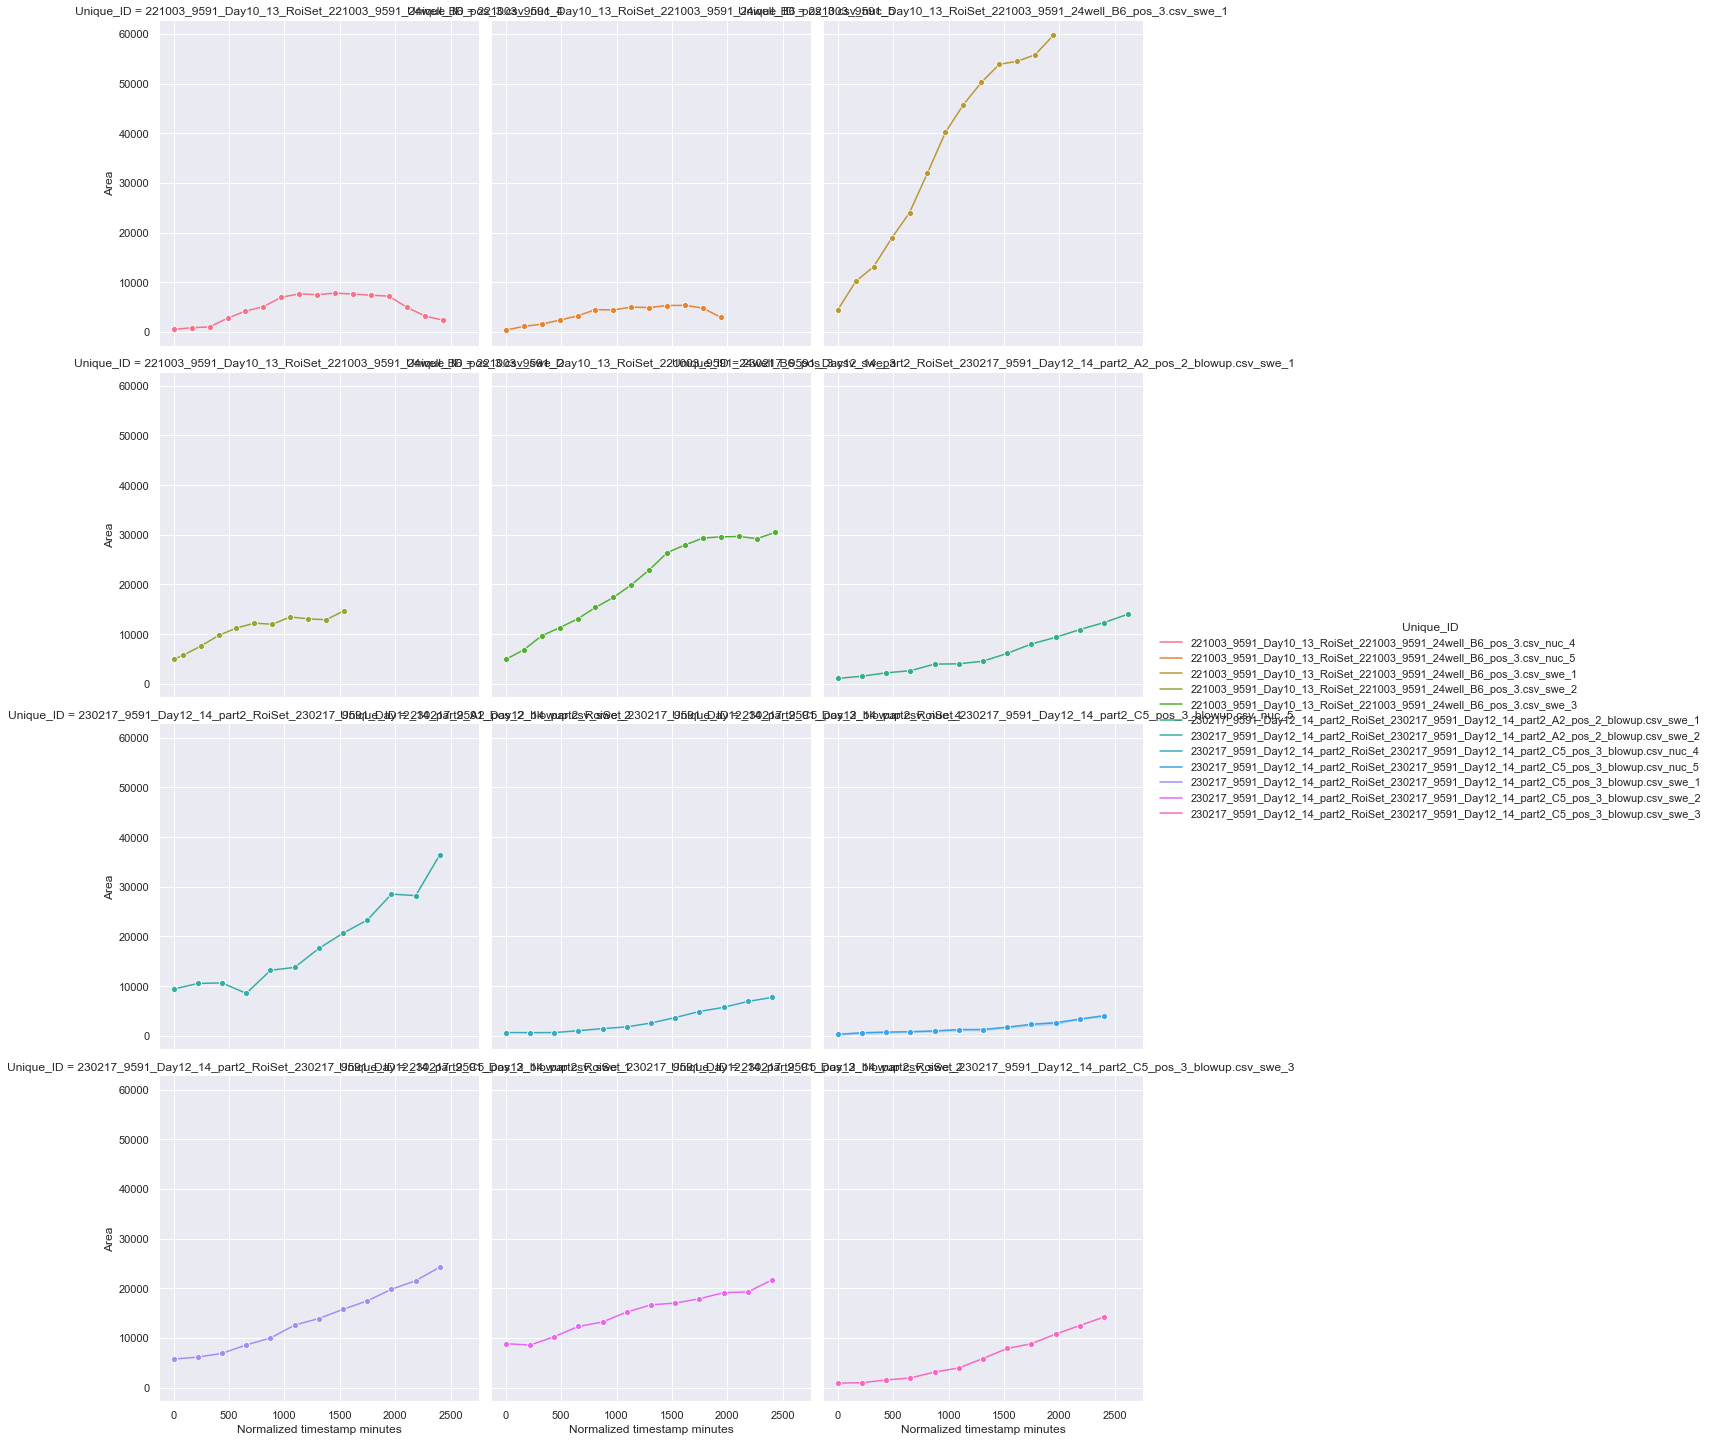

In [15]:
# Exploration cell 

sns.relplot(x="Normalized timestamp minutes", y="Area", col="Unique_ID", 
            hue="Unique_ID",
            col_wrap=3,
            kind="line",
            marker="o",
            data=start_frame_normalized_df_blowup)

C:\Users\Samuel\anaconda3\lib\site-packages\pandas\core\indexing.py:1637: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_block(indexer, value, name)


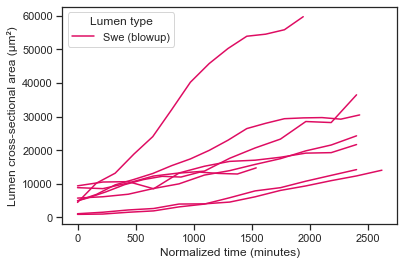

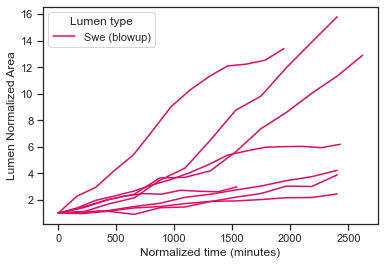

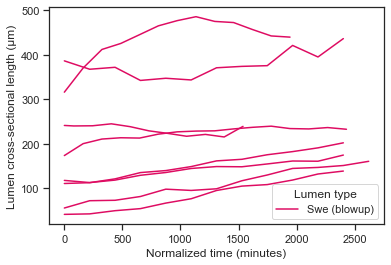

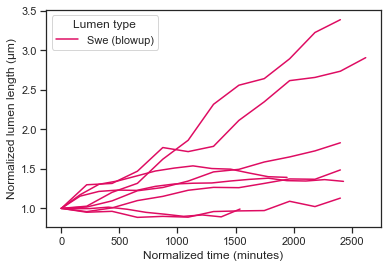

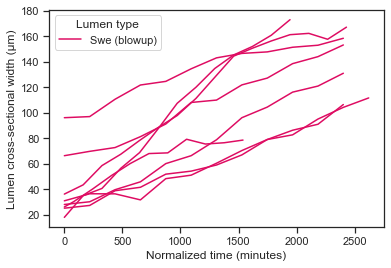

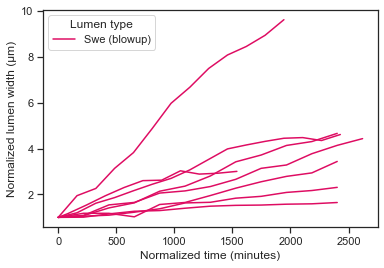

In [16]:
# Plotting cell for the paper

param_list = ["Area", "Normalized Area",
              "Major", "Normalized Major", "Minor", "Normalized Minor"]
#lumen_type_list = ["Nuc", "Swe"]
palette_blowup = ["xkcd:cerise"]

# Area for the blowup organoid may not be the optimal parameter, since I sometimes have to delineate arbitrary cavities for measurement 
# (otherwise, I could have to measure the entirety of the organoid, which is not always possible using bright field)
# The Minor axis corresponding to the transversal diameter of the lumens might be the better choice

#graphs_folder = "C:\\Users\\Samuel\\Dropbox (E22E27)\\Pancreatic_organoids_lumen_paper\\Measurements\\Clear_microlumen_swelling_rate\\Graphs\\"
graphs_folder = "./Graphs/"

# For plotting purposes, rename the location type 
start_frame_normalized_df_blowup["Location_type"].loc[swe_only_mask] = "Swe (blowup)"

with sns.axes_style("ticks"):
    ## Every lumen together
    for param in param_list:
        param_savename = param
        plt.figure()
        g = sns.lineplot(x="Normalized timestamp minutes", y=param, 
                         units="Unique_ID",
                         estimator=None,
                         hue="Location_type",
#                         marker="o",
                         alpha=1,
#                         style="Location_type",
                         palette=palette_blowup,
                        data=start_frame_normalized_df_blowup.loc[swe_only_mask])
           
        if param=="Area":
            plt.ylabel("Lumen cross-sectional area (µm²)")
            ax = plt.gca()
        if param=="Normalized Area":
            plt.ylabel("Lumen {}".format(param)) 
        if param=="Minor":
            plt.ylabel("Lumen cross-sectional width (µm)")
        if param=="Normalized Minor":
            plt.ylabel("Normalized lumen width (µm)")
        if param=="Major":
            plt.ylabel("Lumen cross-sectional length (µm)")
        if param=="Normalized Major":
            plt.ylabel("Normalized lumen length (µm)")

        plt.legend(title='Lumen type')
        plt.xlabel("Normalized time (minutes)")
        savefigure(graphs_folder, param_savename+"_swe_only"+"_blowup")
    
   


 Swelling (Swe) lumen summary:
           Slope    Intercept  Cross-sectional area swelling rate (µm²/hour)  \
count   8.000000     8.000000                                       8.000000   
mean   10.353519  4400.351353                                     621.211150   
std     8.478802  3345.688249                                     508.728113   
min     4.951455  -985.313333                                     297.087310   
25%     5.742579  2948.910714                                     344.554747   
50%     6.887964  5655.662381                                     413.277832   
75%    11.063695  6313.835115                                     663.821724   
max    30.398054  8450.000000                                    1823.883221   

       Cross-sectional area swelling rate (µm²/day)  
count                                      8.000000  
mean                                   14909.067603  
std                                    12209.474719  
min                            

<Figure size 432x288 with 0 Axes>

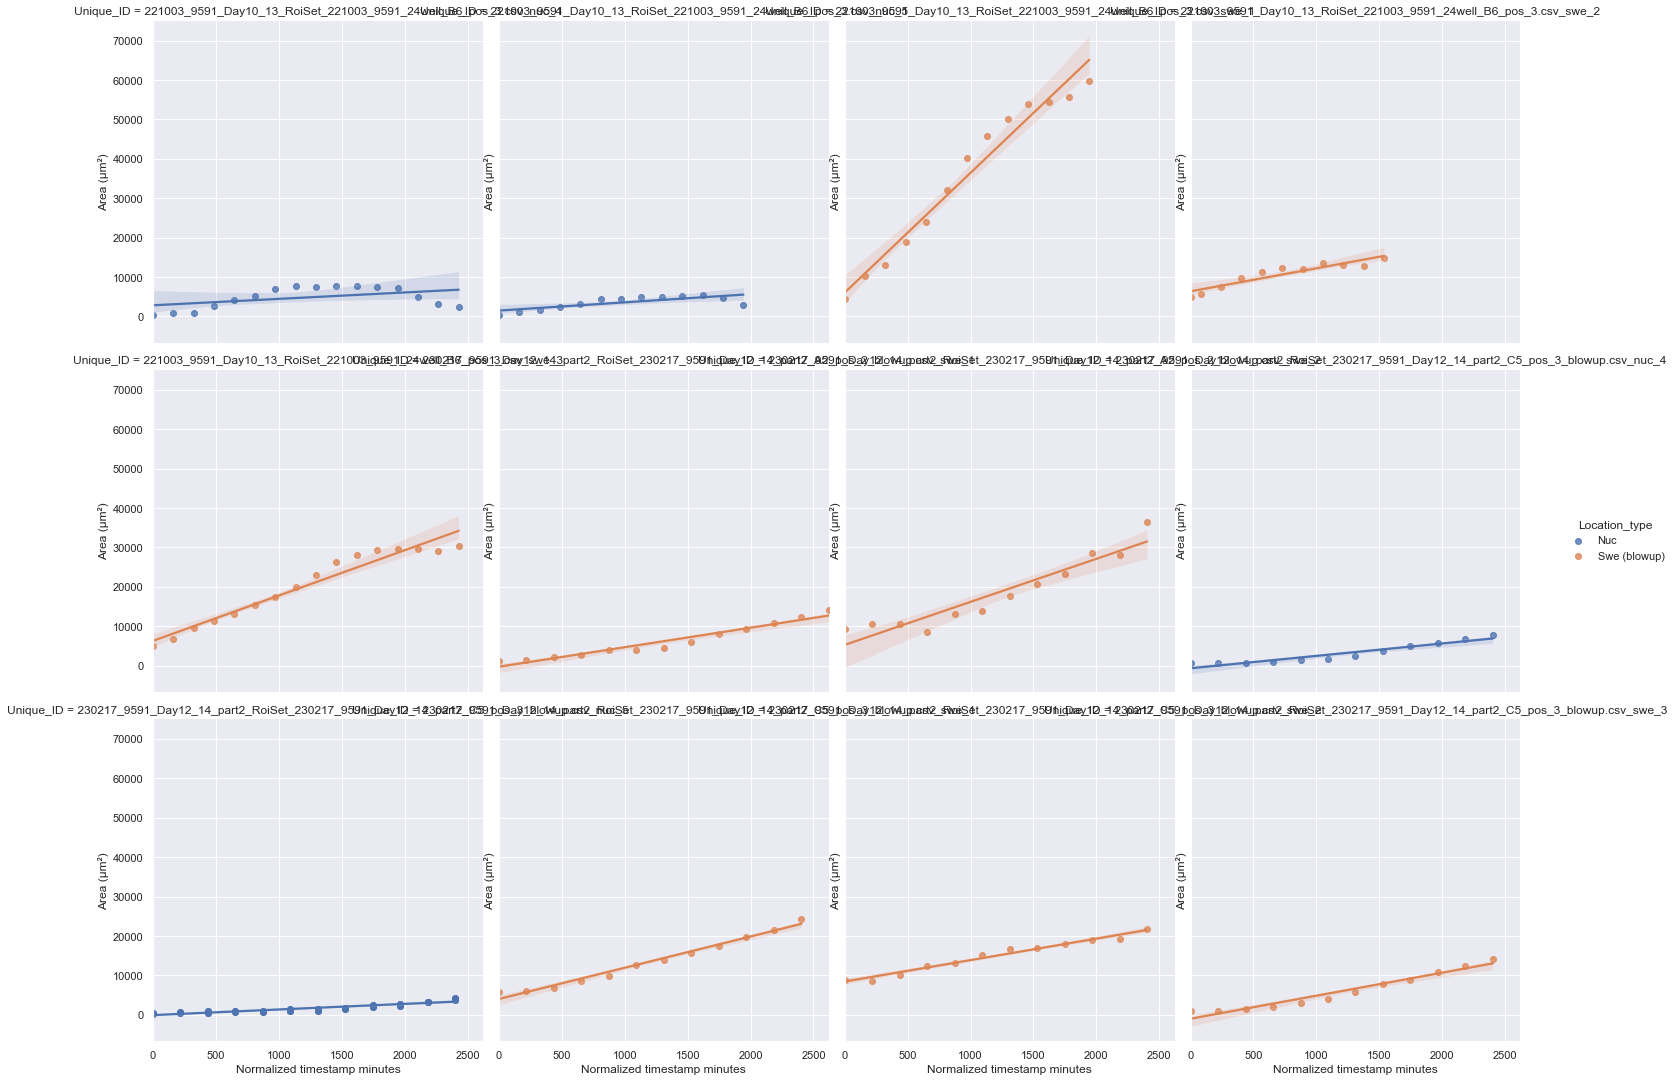

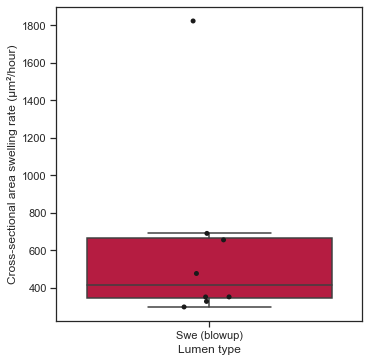

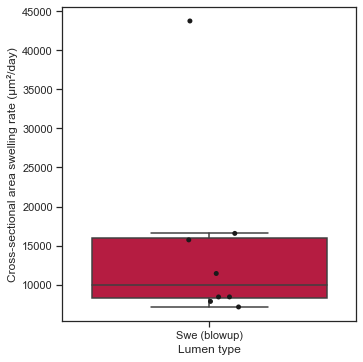

For the blowup lumen type
This is the number of individual organoids measured : 
3
This is the number of individual lumens measured : 
8
--------------------------------------------------


In [17]:
## Computing and plotting the swelling rate for the lumens of the blowup phenotype
# No fusion events in the blowup dataset
# We are only interested in the Swe lumen

   
swe_slope_blowup_no_fus_df = compute_linear_slope(start_frame_normalized_df_blowup.loc[swe_only_mask], "Normalized timestamp minutes",
                                                 "Area", False) 
   
# The slope (i.e the cross-sectional swelling rate) is currently computed in Area (µm²) per (normalized) minutes
# We can compute it in Area (µm²) to make it more understandable

swe_slope_blowup_no_fus_df["Cross-sectional area swelling rate (µm²/hour)"] = swe_slope_blowup_no_fus_df["Slope"] * 60
swe_slope_blowup_no_fus_df["Cross-sectional area swelling rate (µm²/day)"] = swe_slope_blowup_no_fus_df["Slope"] * (60 * 24) 
    
    
# Print some summary statistics about the dataframe
print("\n Swelling (Swe) lumen summary:")
print(swe_slope_blowup_no_fus_df.describe())

# Plot the linear regressions with the post-fusion recordings disabled
plt.figure()
g = sns.lmplot(x="Normalized timestamp minutes", y="Area",
            col="Unique_ID",
            hue="Location_type",
            col_wrap=4,
            data=start_frame_normalized_df_blowup)
plt.ylabel("Area (µm²)")
for ax in g.axes.flat:
    ax.set_ylabel("Area (µm²)")
plt.show()


with sns.axes_style("ticks"):
    g = sns.catplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/hour)", kind="box", 
                    color="xkcd:cherry",
                    data=swe_slope_blowup_no_fus_df,showfliers=False)
    sns.stripplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/hour)",  
                    color="k", 
                    ax=g.ax,
                  alpha=1,
                    data=swe_slope_blowup_no_fus_df)
    plt.xlabel("Lumen type")
#    savefigure(graphs_folder, "swelling_rate_um2_per_hour_together")
    sns.despine(top=False,right=False, left=False,bottom=False)
    plt.show()

    
with sns.axes_style("ticks"):
    g = sns.catplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/day)", kind="box", 
                    color="xkcd:cherry",
                    data=swe_slope_blowup_no_fus_df,showfliers=False)
    sns.stripplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/day)",  
                    color="k", 
                    ax=g.ax,
                  alpha=1,
                    data=swe_slope_blowup_no_fus_df)
    plt.xlabel("Lumen type")
#    savefigure(graphs_folder, "swelling_rate_um2_per_hour_together")
    sns.despine(top=False,right=False, left=False,bottom=False)
    plt.show()
    
# Reporting here the counts for the blowup phenotypes excluding fusion events
print("For the blowup lumen type")
print("This is the number of individual organoids measured : ")
print(len(start_frame_normalized_df_blowup["File_label"].loc[swe_only_mask].unique()))
print("This is the number of individual lumens measured : ")                               
print(len(start_frame_normalized_df_blowup["Unique_ID"].loc[swe_only_mask].unique()))
print("-"*50)



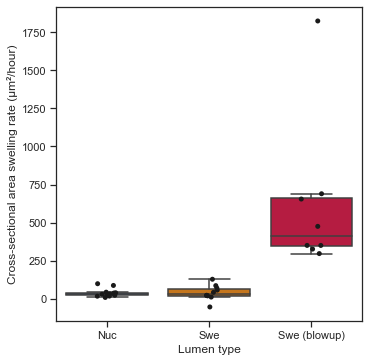

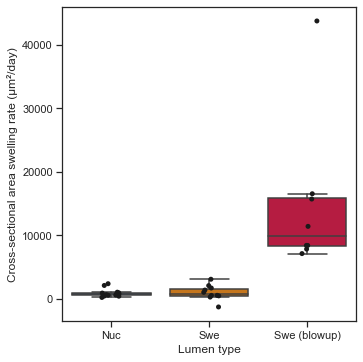

In [18]:
# Contrast the cross-sectional swelling rates for the regular lumens and the blowup phenotypes

## We temporarily replace the location type of the blowup slope dataframe for ease of plotting
swe_slope_blowup_no_fus_df["Location_type"] = "Swe (blowup)"
palette = ["xkcd:medium blue", "xkcd:pumpkin", "xkcd:cherry"]
with sns.axes_style("ticks"):
    g = sns.catplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/hour)", kind="box", 
                    data=pd.concat([slope_no_fus_df,swe_slope_blowup_no_fus_df]),
                    palette=palette,
                   showfliers=False)
    sns.stripplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/hour)",  
                    color="k", 
                    ax=g.ax,
                  alpha=1,
                    data=pd.concat([slope_no_fus_df,swe_slope_blowup_no_fus_df]))
    plt.xlabel("Lumen type")
    sns.despine(top=False,right=False, left=False,bottom=False)
    savefigure(graphs_folder, "swelling_rate_um2_per_hour_normal_and_blowup")

    
    g = sns.catplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/day)", kind="box", 
                    data=pd.concat([slope_no_fus_df,swe_slope_blowup_no_fus_df]),
                    palette=palette,
                   showfliers=False)
    sns.stripplot(x="Location_type", y="Cross-sectional area swelling rate (µm²/day)",  
                    color="k", 
                    ax=g.ax,
                  alpha=1,
                    data=pd.concat([slope_no_fus_df,swe_slope_blowup_no_fus_df]))
    plt.xlabel("Lumen type")
    sns.despine(top=False,right=False, left=False,bottom=False)
    savefigure(graphs_folder, "swelling_rate_um2_per_day_normal_and_blowup")


Warning less than 2 points to perform the regression, returning NaN for  ['230217_9591_Day12_14_part2_RoiSet_A2_pos_1.csv_swe_3']

 Nucleating (Nuc) lumen summary:
           Slope  Intercept  Major axis swelling rate (µm/hour)  \
count  14.000000  14.000000                           14.000000   
mean    0.021892  33.979816                            1.313542   
std     0.013507  20.633318                            0.810408   
min     0.002336  10.335695                            0.140189   
25%     0.014098  20.537814                            0.845867   
50%     0.016655  29.232082                            0.999303   
75%     0.022723  38.577514                            1.363379   
max     0.047792  88.206133                            2.867509   

       Major axis swelling rate (µm/day)  
count                          14.000000  
mean                           31.525012  
std                            19.449801  
min                             3.364546  
25%              

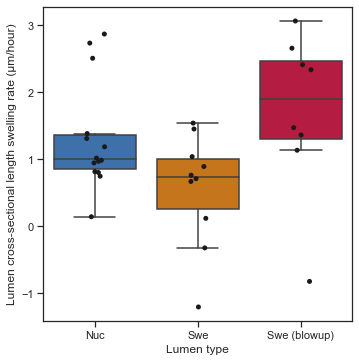

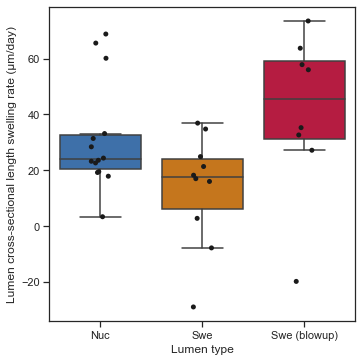

In [19]:
## Computing and plotting the increase of the major axis rate for the lumens of the blowup phenotype
# No fusion events in the blowup dataset


# We can compute for both nuc and swe for the non-blowup phenotypes - excluding fusion events
slope_df_no_fus_list = []
for lumen_type in ["Nuc", "Swe"]:
    slope_df = compute_linear_slope(start_frame_normalized_df_230217.loc[(start_frame_normalized_df_230217["Location_type"] == lumen_type) & start_frame_normalized_df_230217["Allowed flags if no/before fusion"] == True],
                                   "Normalized timestamp minutes", "Major", plot_on=False)
    slope_df_no_fus_list.append(slope_df)

# Separate the df for further separate use

nuc_slope_no_fus_df_major = slope_df_no_fus_list[0]
swe_slope_no_fus_df_major = slope_df_no_fus_list[1]

# We are only interested in the Swe lumen for the blowup

   
swe_slope_blowup_no_fus_df_major = compute_linear_slope(start_frame_normalized_df_blowup.loc[swe_only_mask], "Normalized timestamp minutes",
                                                 "Major", False) 


# The slope (i.e the minor axis swelling rate) is currently computed in µm per (normalized) minutes
# We can compute it in µm/hour to make it more understandable

nuc_slope_no_fus_df_major["Major axis swelling rate (µm/hour)"] = nuc_slope_no_fus_df_major["Slope"] * 60
swe_slope_no_fus_df_major["Major axis swelling rate (µm/hour)"] = swe_slope_no_fus_df_major["Slope"] * 60
swe_slope_blowup_no_fus_df_major["Major axis swelling rate (µm/hour)"] = swe_slope_blowup_no_fus_df_major["Slope"] * 60
    
# We can also compute it in µm/day since the major axis swelling rate is not immediately large

nuc_slope_no_fus_df_major["Major axis swelling rate (µm/day)"] = nuc_slope_no_fus_df_major["Slope"] * 60 * 24
swe_slope_no_fus_df_major["Major axis swelling rate (µm/day)"] = swe_slope_no_fus_df_major["Slope"] * 60 * 24
swe_slope_blowup_no_fus_df_major["Major axis swelling rate (µm/day)"] = swe_slope_blowup_no_fus_df_major["Slope"] * 60 * 24
    
    

# Change the location type for the blowup dataset for ease of plotting    
swe_slope_blowup_no_fus_df_major["Location_type"] = "Swe (blowup)"
    
    
# Print some summary statistics about the dataframes
print("\n Nucleating (Nuc) lumen summary:")
print(nuc_slope_no_fus_df_major.describe())
print("\n Swelling (Swe) lumen summary:")
print(swe_slope_no_fus_df_major.describe())
print("\n Swelling (Swe blowup) lumen summary:")
print(swe_slope_blowup_no_fus_df_major.describe())

# Plot the linear regressions with the post-fusion recordings disabled

palette = ["xkcd:medium blue", "xkcd:pumpkin", "xkcd:cherry"]
param_list = ["Major axis swelling rate (µm/hour)", "Major axis swelling rate (µm/day)"]

with sns.axes_style("ticks"):
    for param in param_list:
        g = sns.catplot(x="Location_type", y=param, kind="box", 
                        data=pd.concat([nuc_slope_no_fus_df_major, swe_slope_no_fus_df_major, swe_slope_blowup_no_fus_df_major]),
                        palette=palette,
                       showfliers=False)
        sns.stripplot(x="Location_type", y=param,  
                        color="k", 
                        ax=g.ax,
                      alpha=1,
                        data=pd.concat([nuc_slope_no_fus_df_major, swe_slope_no_fus_df_major, swe_slope_blowup_no_fus_df_major]))
        plt.xlabel("Lumen type")
        if param=="Major axis swelling rate (µm/hour)":
            plt.ylabel("Lumen cross-sectional length swelling rate (µm/hour)")
        if param=="Major axis swelling rate (µm/day)":
            plt.ylabel("Lumen cross-sectional length swelling rate (µm/day)")
        sns.despine(top=False,right=False, left=False,bottom=False)
        #plt.show()
        savefigure(graphs_folder, "major_swelling_rate_um_per_day_normal_and_blowup")


Warning less than 2 points to perform the regression, returning NaN for  ['230217_9591_Day12_14_part2_RoiSet_A2_pos_1.csv_swe_3']

 Nucleating (Nuc) lumen summary:
           Slope  Intercept  Minor axis swelling rate (µm/hour)  \
count  14.000000  14.000000                           14.000000   
mean    0.008625   9.816321                            0.517510   
std     0.004467   3.890896                            0.268009   
min     0.003086   3.283511                            0.185161   
25%     0.006377   7.237095                            0.382605   
50%     0.007257   9.261082                            0.435417   
75%     0.009993  12.167103                            0.599586   
max     0.020911  16.850022                            1.254644   

       Minor axis swelling rate (µm/day)  
count                          14.000000  
mean                           12.420242  
std                             6.432212  
min                             4.443863  
25%              

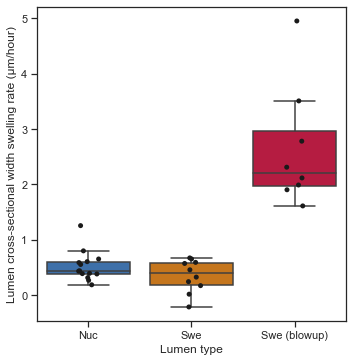

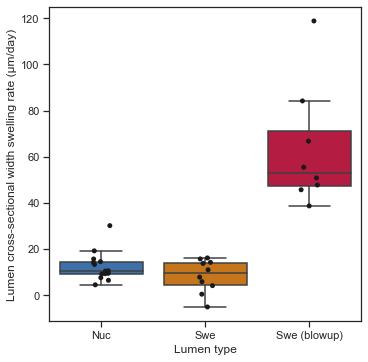

In [20]:
## Computing and plotting the increase of the minor axis rate for the lumens of the blowup phenotype
# No fusion events in the blowup dataset


# We can compute for both nuc and swe for the non-blowup phenotypes - excluding fusion events
slope_df_no_fus_list = []
for lumen_type in ["Nuc", "Swe"]:
    slope_df = compute_linear_slope(start_frame_normalized_df_230217.loc[(start_frame_normalized_df_230217["Location_type"] == lumen_type) & start_frame_normalized_df_230217["Allowed flags if no/before fusion"] == True],
                                   "Normalized timestamp minutes", "Minor", plot_on=False)
    slope_df_no_fus_list.append(slope_df)

# Separate the df for further separate use

nuc_slope_no_fus_df_minor = slope_df_no_fus_list[0]
swe_slope_no_fus_df_minor = slope_df_no_fus_list[1]

# We are only interested in the Swe lumen for the blowup

   
swe_slope_blowup_no_fus_df_minor = compute_linear_slope(start_frame_normalized_df_blowup.loc[swe_only_mask], "Normalized timestamp minutes",
                                                 "Minor", False) 


# The slope (i.e the minor axis swelling rate) is currently computed in µm per (normalized) minutes
# We can compute it in µm/hour to make it more understandable

nuc_slope_no_fus_df_minor["Minor axis swelling rate (µm/hour)"] = nuc_slope_no_fus_df_minor["Slope"] * 60
swe_slope_no_fus_df_minor["Minor axis swelling rate (µm/hour)"] = swe_slope_no_fus_df_minor["Slope"] * 60
swe_slope_blowup_no_fus_df_minor["Minor axis swelling rate (µm/hour)"] = swe_slope_blowup_no_fus_df_minor["Slope"] * 60
    
# We can also compute it in µm/day since the minor axis swelling rate is not immediately large

nuc_slope_no_fus_df_minor["Minor axis swelling rate (µm/day)"] = nuc_slope_no_fus_df_minor["Slope"] * 60 * 24
swe_slope_no_fus_df_minor["Minor axis swelling rate (µm/day)"] = swe_slope_no_fus_df_minor["Slope"] * 60 * 24
swe_slope_blowup_no_fus_df_minor["Minor axis swelling rate (µm/day)"] = swe_slope_blowup_no_fus_df_minor["Slope"] * 60 * 24
    
    

# Change the location type for the blowup dataset for ease of plotting    
swe_slope_blowup_no_fus_df_minor["Location_type"] = "Swe (blowup)"
    
    
# Print some summary statistics about the dataframes
print("\n Nucleating (Nuc) lumen summary:")
print(nuc_slope_no_fus_df_minor.describe())
print("\n Swelling (Swe) lumen summary:")
print(swe_slope_no_fus_df_minor.describe())
print("\n Swelling (Swe blowup) lumen summary:")
print(swe_slope_blowup_no_fus_df_minor.describe())

# Plot the linear regressions with the post-fusion recordings disabled

palette = ["xkcd:medium blue", "xkcd:pumpkin", "xkcd:cherry"]
param_list = ["Minor axis swelling rate (µm/hour)", "Minor axis swelling rate (µm/day)"]

with sns.axes_style("ticks"):
    for param in param_list:
        g = sns.catplot(x="Location_type", y=param, kind="box", 
                        data=pd.concat([nuc_slope_no_fus_df_minor, swe_slope_no_fus_df_minor, swe_slope_blowup_no_fus_df_minor]),
                        palette=palette,
                       showfliers=False)
        sns.stripplot(x="Location_type", y=param,  
                        color="k", 
                        ax=g.ax,
                      alpha=1,
                        data=pd.concat([nuc_slope_no_fus_df_minor, swe_slope_no_fus_df_minor, swe_slope_blowup_no_fus_df_minor]))
        plt.xlabel("Lumen type")
        if param=="Minor axis swelling rate (µm/hour)":
            plt.ylabel("Lumen cross-sectional width swelling rate (µm/hour)")
        if param=="Minor axis swelling rate (µm/day)":
            plt.ylabel("Lumen cross-sectional width swelling rate (µm/day)")
        sns.despine(top=False,right=False, left=False,bottom=False)
        #plt.show()
        savefigure(graphs_folder, "minor_swelling_rate_um_per_day_normal_and_blowup")


# Reporting some statistical values

In [21]:
tt = slope_no_fus_df.groupby(["Location_type"]).agg([np.mean,np.median, np.std])
print(tt)


print(50*'*')
print(50*'*')

tt2 = swe_slope_blowup_no_fus_df.groupby(["Location_type"]).agg([np.mean,np.median, np.std])
print(tt2)

                  Slope                        Intercept               \
                   mean    median       std         mean       median   
Location_type                                                           
Nuc            0.622464  0.499141  0.428235   226.352551   183.380364   
Swe            0.685240  0.549844  0.820452  1794.429963  1874.235606   

                           Cross-sectional area swelling rate (µm²/hour)  \
                       std                                          mean   
Location_type                                                              
Nuc             274.916163                                     37.347839   
Swe            1258.511582                                     41.114415   

                                     \
                  median        std   
Location_type                         
Nuc            29.948454  25.694117   
Swe            32.990668  49.227096   

              Cross-sectional area swelling rate (µm²/day